# Analyze Merged SSGA Data
This notebook loads the merged dataset downloaded from Weights & Biases.

In [1]:
import pandas as pd
import os
from dotenv import load_dotenv

# Load environment variables from .env if present
load_dotenv()

# Construct the path using WANDB_DIR
wandb_dir = os.environ.get("WANDB_DIR", "./")
data_path = os.path.join(wandb_dir, "data", "lck2wafo_dment0yi", "merged_agent_stats.parquet")

print(f"Loading data from {data_path}...")
try:
    # Load the parquet file (much faster for large datasets)
    df = pd.read_parquet(data_path)
except FileNotFoundError:
    # Fallback to the CSV if parquet isn't available for some reason
    csv_path = data_path.replace(".parquet", ".csv.gz")
    print(f"Parquet not found. Falling back to CSV: {csv_path}")
    df = pd.read_csv(csv_path)

print(f"Dataset shape: {df.shape}")
df.head()

Loading data from /groups/romanczuk/Chirkov_wandb/ssga/data/lck2wafo_dment0yi/merged_agent_stats.parquet...


Dataset shape: (6000000, 13)


,group_id,agent_id,age,cumulative_fitness,current_fitness,avg_fitness,gene_priv,gene_soc,gene_none,gene_eve,run_id,close_target_index,step
0,0.0,0.0,1000.0,809.989380,0.811950,0.809989,0.367425,-0.240265,0.075739,-0.644270,lck2wafo,0,999
1,0.0,1.0,1000.0,801.374146,0.793795,0.801374,0.987102,-0.111018,0.310793,0.440495,lck2wafo,0,999
2,0.0,2.0,1000.0,836.685059,0.828782,0.836685,0.150497,0.472290,-0.321096,-0.453458,lck2wafo,0,999
3,0.0,3.0,1000.0,824.242065,0.833711,0.824242,0.067888,-0.256189,-0.435010,0.634646,lck2wafo,0,999
4,0.0,4.0,1000.0,797.704956,0.835471,0.797705,0.249322,-0.082900,-0.556916,0.113567,lck2wafo,0,999


Calculating statistics and plotting...


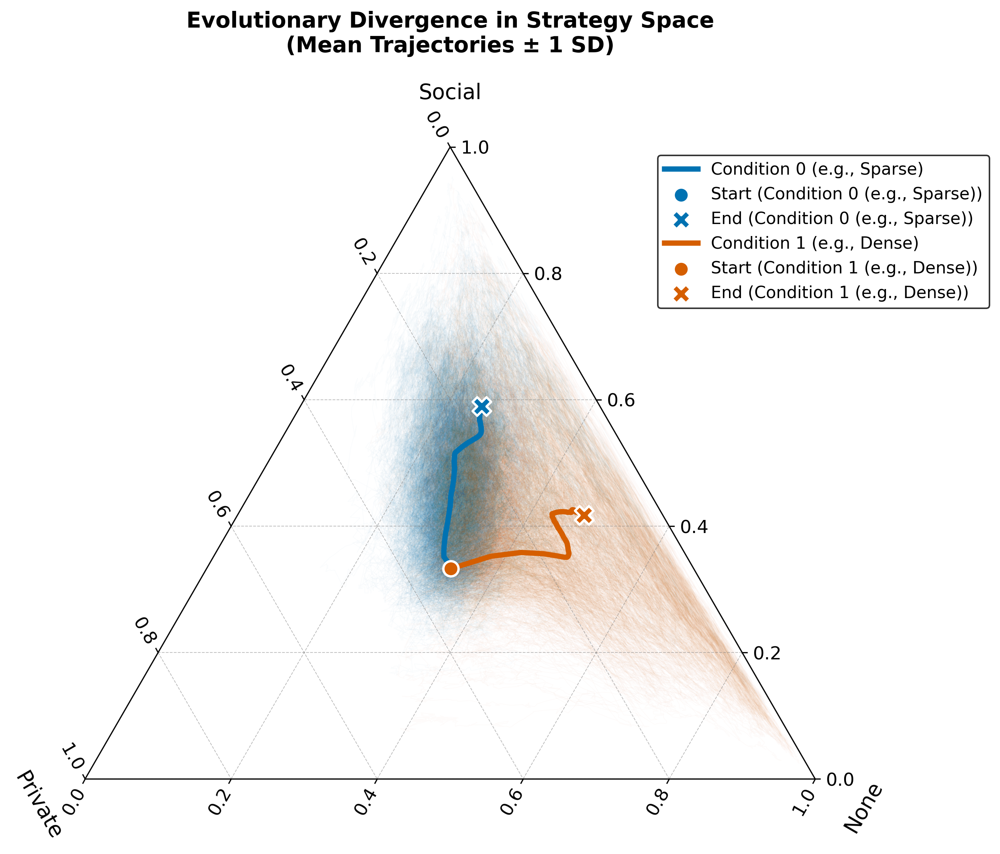

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mpltern
from scipy.special import softmax

# --- 1. Data Prep ---
genes = df[['gene_priv', 'gene_soc', 'gene_none']].values
probs = softmax(genes, axis=1)
df[['p_priv', 'p_soc', 'p_none']] = probs

max_step = 199_999
group_trajectories = df[df.step < max_step].groupby(
    ['run_id', 'group_id', 'step', 'close_target_index']
)[['p_priv', 'p_soc', 'p_none']].mean().reset_index()

group_trajectories = group_trajectories.sort_values(['run_id', 'group_id', 'step'])

# --- 2. Setup Publication Aesthetics ---
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 14,
    'legend.fontsize': 11,
    'figure.dpi': 300, 
    'font.family': 'sans-serif'
})

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='ternary')

conditions = [0, 1] 
colors = {0: '#0072B2', 1: '#D55E00'} # Blue and Vermillion
labels = {0: 'Condition 0 (e.g., Sparse)', 1: 'Condition 1 (e.g., Dense)'}

print("Calculating statistics and plotting...")

for cond in conditions:
    cond_data = group_trajectories[group_trajectories['close_target_index'] == cond]
    color = colors[cond]
    
    # A. Plot the "Flow Envelope" (Empirical Variance)
    for (run_id, group_id), group_df in cond_data.groupby(['run_id', 'group_id']):
        ax.plot(group_df['p_soc'], group_df['p_priv'], group_df['p_none'], 
                color=color, alpha=0.02, linewidth=0.5, zorder=1)

    # B. Calculate Mean and Standard Deviation over time
    step_stats = cond_data.groupby('step').agg({
        'p_soc': ['mean', 'std'],
        'p_priv': ['mean', 'std'],
        'p_none': ['mean', 'std']
    }).reset_index()
    
    step_stats.columns = ['step', 'soc_mean', 'soc_std', 'priv_mean', 'priv_std', 'none_mean', 'none_std']
    step_stats = step_stats.sort_values('step')
    
    # C. Plot the Thick Mean Trajectory
    ax.plot(step_stats['soc_mean'], step_stats['priv_mean'], step_stats['none_mean'], 
            color=color, linewidth=3.5, label=labels[cond], zorder=4)
    
    # D. Robust Manual Error Bars (Geometric Simplex Stars)
    sparse_interval = 25_000
    downsampled = step_stats[step_stats['step'] % sparse_interval == 0]
    
    for _, row in downsampled.iterrows():
        t, l, r = row['soc_mean'], row['priv_mean'], row['none_mean']
        dt, dl, dr = row['soc_std'], row['priv_std'], row['none_std']
        
        # Social (Top) Error Bar
        ax.plot([t - dt, t + dt], [l + dt/2, l - dt/2], [r + dt/2, r - dt/2], 
                color='black', linewidth=1.2, alpha=0.5, zorder=5)
        # Private (Left) Error Bar
        ax.plot([t + dl/2, t - dl/2], [l - dl, l + dl], [r + dl/2, r - dl/2], 
                color='black', linewidth=1.2, alpha=0.5, zorder=5)
        # None (Right) Error Bar
        ax.plot([t + dr/2, t - dr/2], [l + dr/2, l - dr/2], [r - dr, r + dr], 
                color='black', linewidth=1.2, alpha=0.5, zorder=5)
    
    # E. Start and End Markers for the Mean Path
    ax.scatter(step_stats['soc_mean'].iloc[0], step_stats['priv_mean'].iloc[0], step_stats['none_mean'].iloc[0], 
               color=color, marker='o', s=100, edgecolor='white', linewidth=1.5, zorder=6, label=f'Start ({labels[cond]})')
    ax.scatter(step_stats['soc_mean'].iloc[-1], step_stats['priv_mean'].iloc[-1], step_stats['none_mean'].iloc[-1], 
               color=color, marker='X', s=150, edgecolor='white', linewidth=1.5, zorder=6, label=f'End ({labels[cond]})')

# --- 3. Final Formatting ---
ax.set_tlabel("Social")
ax.set_llabel("Private")
ax.set_rlabel("None")

ax.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)
ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.0), frameon=True, edgecolor='black')

plt.title("Evolutionary Divergence in Strategy Space\n(Mean Trajectories ± 1 SD)", pad=20, weight='bold')
plt.tight_layout()

plt.show()

Classifying trajectories...
Plotting classified flows...


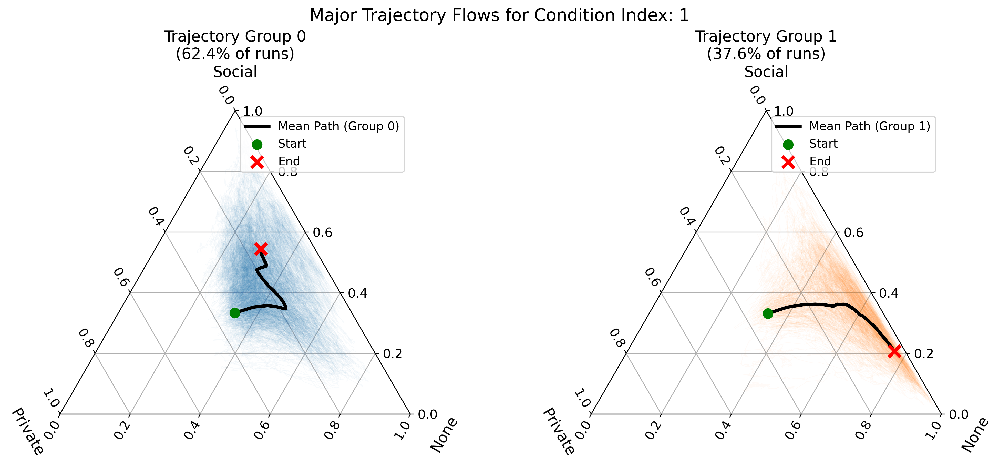

In [3]:
from sklearn.cluster import KMeans
unique_indices = df['close_target_index'].unique()
# 1. Select the specific condition you want to analyze
# (Change 0 to whichever index corresponds to the condition you are investigating)
target_condition = unique_indices[1] 
cond_data = group_trajectories[group_trajectories['close_target_index'] == target_condition].copy()

# 2. Extract final states to classify the trajectories
print("Classifying trajectories...")
final_states = cond_data.groupby(['run_id', 'group_id']).last().reset_index()

# 3. Classify into 2 major groups based on their end-state coordinates
kmeans = KMeans(n_clusters=2, random_state=42)
# We only need two coordinates since the third is linearly dependent (p_soc + p_priv + p_none = 1)
final_states['trajectory_class'] = kmeans.fit_predict(final_states[['p_soc', 'p_priv']])

# 4. Merge the trajectory class labels back to the full dataset
class_mapping = final_states[['run_id', 'group_id', 'trajectory_class']]
cond_data = cond_data.merge(class_mapping, on=['run_id', 'group_id'])

# 5. Visualization: Side-by-side ternary plots for the two groups
fig = plt.figure(figsize=(14, 6))
group_colors = ['#1f77b4', '#ff7f0e'] # Blue and Orange

print("Plotting classified flows...")
for class_id in [0, 1]:
    # Create subplots for each class
    ax = fig.add_subplot(1, 2, class_id + 1, projection='ternary')
    class_df = cond_data[cond_data['trajectory_class'] == class_id]
    
    # A. Plot individual faint trajectories for this specific class
    for (run_id, group_id), group_df in class_df.groupby(['run_id', 'group_id']):
        ax.plot(group_df['p_soc'], group_df['p_priv'], group_df['p_none'], 
                color=group_colors[class_id], alpha=0.03, linewidth=0.5)
        
    # B. Calculate and plot the MEAN trajectory strictly for this class
    mean_traj = class_df.groupby('step')[['p_priv', 'p_soc', 'p_none']].mean().reset_index().sort_values('step')
    
    ax.plot(mean_traj['p_soc'], mean_traj['p_priv'], mean_traj['p_none'], 
            color='black', linewidth=3, label=f"Mean Path (Group {class_id})")
    
    # C. Start (o) and End (x) markers for the mean path
    ax.scatter(mean_traj['p_soc'].iloc[0], mean_traj['p_priv'].iloc[0], mean_traj['p_none'].iloc[0], 
               color='green', marker='o', s=80, zorder=5, label='Start')
    ax.scatter(mean_traj['p_soc'].iloc[-1], mean_traj['p_priv'].iloc[-1], mean_traj['p_none'].iloc[-1], 
               color='red', marker='x', s=120, zorder=5, linewidths=3, label='End')

    # D. Formatting
    ax.set_tlabel("Social")
    ax.set_llabel("Private")
    ax.set_rlabel("None")
    ax.grid()
    
    # Calculate what percentage of runs fell into this group
    pct = (len(final_states[final_states['trajectory_class'] == class_id]) / len(final_states)) * 100
    ax.set_title(f"Trajectory Group {class_id}\n({pct:.1f}% of runs)")
    ax.legend(loc='upper right')

plt.suptitle(f"Major Trajectory Flows for Condition Index: {target_condition}", fontsize=16)
plt.tight_layout()
plt.show()

Calculating unified stream fields...


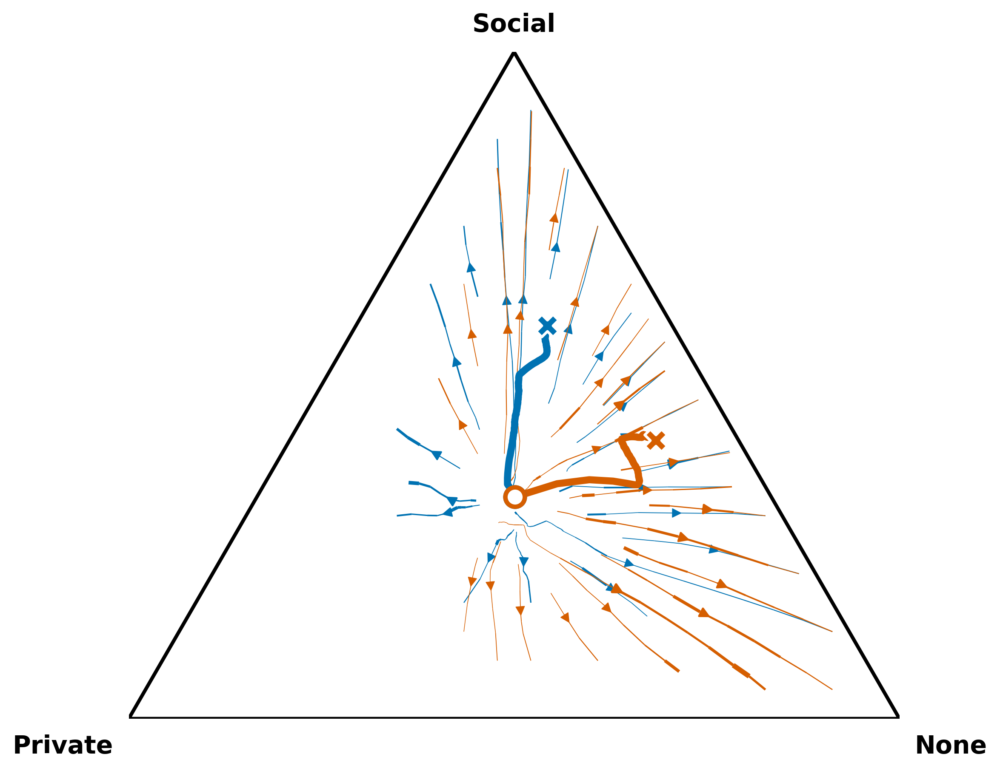

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from scipy.special import softmax
from scipy.interpolate import griddata

# ==========================================
# 1. Prepare Probabilities
# ==========================================
df_flow = df.copy()
genes_cols = ['gene_priv', 'gene_soc', 'gene_none']
probs = softmax(df_flow[genes_cols].values, axis=1)

df_flow['prob_priv'] = probs[:, 0]
df_flow['prob_soc'] = probs[:, 1]
df_flow['prob_none'] = probs[:, 2]

# Identify the first two conditions to plot
conditions = df_flow['close_target_index'].unique()[:2]
colors = {conditions[0]: '#0072B2', conditions[1]: '#D55E00'} # Blue and Vermillion
labels = {conditions[0]: f'Condition {conditions[0]}', conditions[1]: f'Condition {conditions[1]}'}

# ==========================================
# 2. Setup Figure & Triangle Geometry
# ==========================================
fig, ax = plt.subplots(figsize=(8, 7))
plt.rcParams.update({'font.size': 12})

# Triangle Geometry: Left (Private)=(0, 0), Right (None)=(1, 0), Top (Social)=(0.5, sqrt(3)/2)
H = np.sqrt(3) / 2

print("Calculating unified stream fields...")

for cond in conditions:
    cond_df = df_flow[df_flow['close_target_index'] == cond].copy()

    # Aggregate to group-level step data
    df_group_steps = cond_df.groupby(['run_id', 'group_id', 'step'])[['prob_priv', 'prob_soc', 'prob_none']].mean().reset_index()
    df_group_steps = df_group_steps.sort_values(['run_id', 'group_id', 'step'])

    # ==========================================
    # 3. Calculate Smooth Vectors (Reduced Window)
    # ==========================================
    # Reduced window size to prevent washing out the velocity
    window_size = 2_000 
    
    df_group_steps['d_priv'] = df_group_steps.groupby(['run_id', 'group_id'])['prob_priv'].diff()
    df_group_steps['d_soc'] = df_group_steps.groupby(['run_id', 'group_id'])['prob_soc'].diff()
    df_group_steps['d_none'] = df_group_steps.groupby(['run_id', 'group_id'])['prob_none'].diff()

    # Smooth the deltas
    for col in ['d_priv', 'd_soc', 'd_none']:
        df_group_steps[col] = df_group_steps.groupby(['run_id', 'group_id'])[col].transform(lambda x: x.rolling(window_size, min_periods=1).mean())

    df_clean = df_group_steps.dropna(subset=['d_priv']).copy()

    # ==========================================
    # 4. Transform Ternary to Cartesian 2D
    # ==========================================
    x = df_clean['prob_none'] + 0.5 * df_clean['prob_soc']
    y = H * df_clean['prob_soc']
    
    dx = df_clean['d_none'] + 0.5 * df_clean['d_soc']
    dy = H * df_clean['d_soc']

    # ==========================================
    # 5. Interpolate onto Regular Grid
    # ==========================================
    grid_res = 150
    grid_x, grid_y = np.meshgrid(np.linspace(0, 1, grid_res), np.linspace(0, H, grid_res))
    
    points = np.column_stack((x, y))
    grid_dx = griddata(points, dx, (grid_x, grid_y), method='linear')
    grid_dy = griddata(points, dy, (grid_x, grid_y), method='linear')
    
    # Calculate speed for stream thickness
    speed = np.sqrt(grid_dx**2 + grid_dy**2)
    
    # Normalize speed to create a clean linewidth mapping (min 0.3px, max 3.5px)
    lw = 0.3 + 3.2 * (speed / np.nanmax(speed))

    # Mask outside triangle
    outside_triangle = (grid_y < 0) | (grid_y > np.sqrt(3) * grid_x) | (grid_y > np.sqrt(3) * (1 - grid_x))
    grid_dx[outside_triangle] = np.nan
    grid_dy[outside_triangle] = np.nan

    # ==========================================
    # 6. Plotting Streams & Mean Trajectory
    # ==========================================
    # Plot the stream field
    # We use a slightly lower density so both fields remain visible
    ax.streamplot(grid_x, grid_y, grid_dx, grid_dy, 
                  color=colors[cond], linewidth=lw, 
                  density=0.8, arrowsize=1.2, zorder=2)
    
    # Calculate and Plot the Main Typical Path (Mean Trajectory)
    mean_traj = df_group_steps.groupby('step')[['prob_priv', 'prob_soc', 'prob_none']].mean().reset_index()
    mean_x = mean_traj['prob_none'] + 0.5 * mean_traj['prob_soc']
    mean_y = H * mean_traj['prob_soc']
    
    # Draw Mean Line
    ax.plot(mean_x, mean_y, color=colors[cond], linewidth=4, zorder=5, solid_capstyle='round')
    # Draw Start and End Points
    ax.scatter(mean_x.iloc[0], mean_y.iloc[0], color='white', edgecolor=colors[cond], marker='o', s=120, linewidth=2.5, zorder=6)
    ax.scatter(mean_x.iloc[-1], mean_y.iloc[-1], color=colors[cond], edgecolor='white', marker='X', s=160, linewidth=1.5, zorder=6, label=f'{labels[cond]} (Mean & Flow)')

# ==========================================
# 7. Final Formatting
# ==========================================
# Draw the physical Triangle outline
triangle = Polygon([[0, 0], [1, 0], [0.5, H]], fill=False, edgecolor='black', linewidth=2, zorder=4)
ax.add_patch(triangle)

# Add corner labels
ax.text(0.5, H + 0.02, "Social", ha='center', va='bottom', fontsize=14, weight='bold')
ax.text(-0.02, -0.02, "Private", ha='right', va='top', fontsize=14, weight='bold')
ax.text(1.02, -0.02, "None", ha='left', va='top', fontsize=14, weight='bold')

# Formatting
ax.axis('off')
ax.set_aspect('equal')
# plt.title("Comparative Strategy Flow Dynamics\n(Line thickness denotes flow velocity)", fontsize=16, weight='bold', pad=20)
# ax.legend(loc='upper right', frameon=True, edgecolor='black', bbox_to_anchor=(1.1, 1))

plt.tight_layout()
plt.show()

Identifying trajectory clusters per condition...
Condition 1: Optimal clusters = 2 (Silhouette Score: 0.501)
Condition 0: Optimal clusters = 2 (Silhouette Score: 0.378)
Plotting clustered aggregate streamlines...


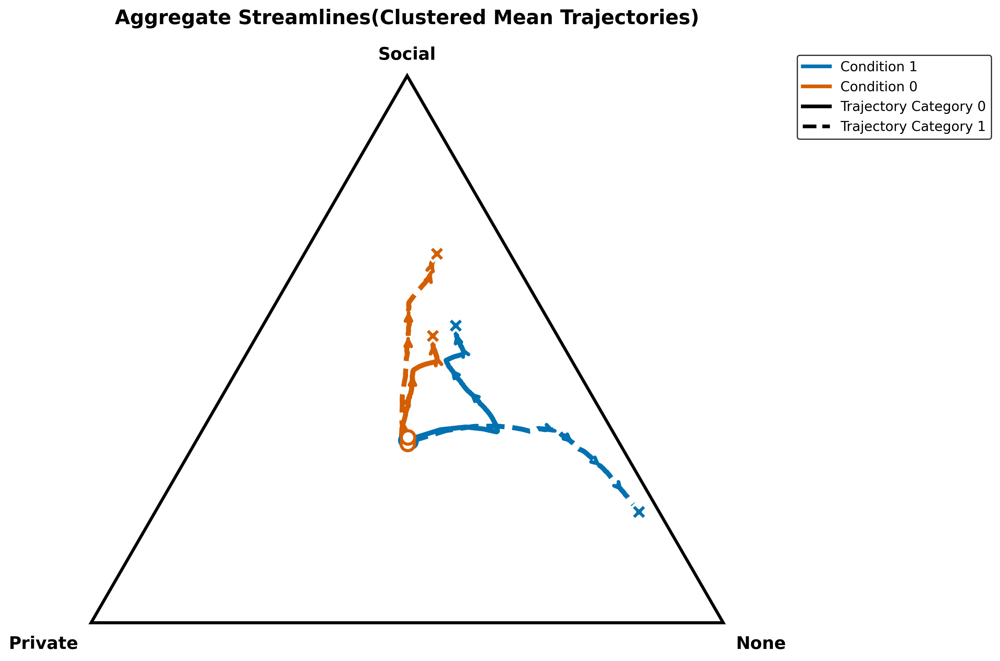

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from scipy.special import softmax
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from matplotlib.lines import Line2D
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)

# ==========================================
# 1. Prepare Probabilities (All Conditions)
# ==========================================
df_flow = df.copy()
genes_cols = ['gene_priv', 'gene_soc', 'gene_none']
probs = softmax(df_flow[genes_cols].values, axis=1)

df_flow['prob_priv'] = probs[:, 0]
df_flow['prob_soc'] = probs[:, 1]
df_flow['prob_none'] = probs[:, 2]

# Aggregate to group-level step data
df_group_steps = df_flow.groupby(['run_id', 'group_id', 'step', 'close_target_index'])[['prob_priv', 'prob_soc', 'prob_none']].mean().reset_index()
df_group_steps = df_group_steps.sort_values(['run_id', 'group_id', 'step'])

# ==========================================
# 2. Robust Clustering per Condition
# ==========================================
print("Identifying trajectory clusters per condition...")

clustered_dfs = []
min_cluster_pct = 0.05 
conditions = df_group_steps['close_target_index'].unique()

for cond in conditions:
    cond_df = df_group_steps[df_group_steps['close_target_index'] == cond].copy()
    
    # Extract spatial summary features for each trajectory
    traj_features = cond_df.groupby(['run_id', 'group_id']).agg({
        'prob_soc': ['mean', 'last'],
        'prob_priv': ['mean', 'last']
    }).reset_index()
    traj_features.columns = ['run_id', 'group_id', 'soc_mean', 'soc_last', 'priv_mean', 'priv_last']
    X = traj_features[['soc_mean', 'soc_last', 'priv_mean', 'priv_last']].values
    
    # Find optimal k
    best_k = 2
    best_score = -1
    for k in range(2, 6):
        if k >= len(X): break
        kmeans = KMeans(n_clusters=k, random_state=42)
        labels = kmeans.fit_predict(X)
        score = silhouette_score(X, labels)
        if score > best_score:
            best_score = score
            best_k = k
            
    print(f"Condition {cond}: Optimal clusters = {best_k} (Silhouette Score: {best_score:.3f})")
    kmeans = KMeans(n_clusters=best_k, random_state=42)
    traj_features['trajectory_class'] = kmeans.fit_predict(X)
    
    # Filter out clusters that are too small
    total_runs = len(traj_features)
    class_counts = traj_features['trajectory_class'].value_counts()
    valid_classes = class_counts[class_counts / total_runs >= min_cluster_pct].index
    
    traj_features = traj_features[traj_features['trajectory_class'].isin(valid_classes)]
    
    # Merge back
    class_mapping = traj_features[['run_id', 'group_id', 'trajectory_class']]
    cond_df = cond_df.merge(class_mapping, on=['run_id', 'group_id'])
    clustered_dfs.append(cond_df)

# Recombine
df_group_steps_clustered = pd.concat(clustered_dfs, ignore_index=True)

# ==========================================
# 3. Visualization Setup
# ==========================================
H = np.sqrt(3) / 2
fig, ax = plt.subplots(figsize=(11, 9))
plt.rcParams.update({'font.size': 12})

print("Plotting clustered aggregate streamlines...")
colors = {conditions[0]: '#0072B2', conditions[1]: '#D55E00'} # Blue & Vermillion
linestyles = ['-', '--', ':', '-.']

# We need to build the legend dynamically
legend_elements = [
    Line2D([0], [0], color=colors[conditions[0]], lw=3, label=f'Condition {conditions[0]}'),
    Line2D([0], [0], color=colors[conditions[1]], lw=3, label=f'Condition {conditions[1]}')
]

for cond in conditions:
    cond_subset = df_group_steps_clustered[df_group_steps_clustered['close_target_index'] == cond]
    classes = cond_subset['trajectory_class'].unique()
    
    for i, class_id in enumerate(sorted(classes)):
        subset = cond_subset[cond_subset['trajectory_class'] == class_id]
        if subset.empty:
            continue
            
        mean_traj = subset.groupby('step')[['prob_priv', 'prob_soc', 'prob_none']].mean().reset_index().sort_values('step')
        
        mx = mean_traj['prob_none'] + 0.5 * mean_traj['prob_soc']
        my = H * mean_traj['prob_soc']
        
        ls = linestyles[i % len(linestyles)]
        
        # Draw thick line for the trajectory
        line, = ax.plot(mx, my, color=colors[cond], linestyle=ls, 
                linewidth=4, zorder=5, solid_capstyle='round')
        
        # Add arrows along the trajectory to indicate streamline flow
        num_arrows = 4
        arrow_indices = np.linspace(0, len(mx)-1, num_arrows+2, dtype=int)[1:-1]
        look_ahead = max(1, len(mx) // 20)
        
        for idx in arrow_indices:
            idx_next = min(len(mx)-1, idx + look_ahead)
            
            # Using annotate for high-quality arrows that match the line color
            ax.annotate('', xy=(mx.iloc[idx_next], my.iloc[idx_next]), 
                        xytext=(mx.iloc[idx], my.iloc[idx]),
                        arrowprops=dict(arrowstyle="->", color=colors[cond], lw=3),
                        zorder=6)
        
        # Start and End points
        ax.scatter(mx.iloc[0], my.iloc[0], color='white', edgecolor=colors[cond], marker='o', s=120, linewidth=2.5, zorder=7)
        ax.scatter(mx.iloc[-1], my.iloc[-1], color=colors[cond], edgecolor='white', marker='X', s=160, linewidth=2, zorder=7)

# Create linestyle legend (we assume max classes per condition is 4 based on linestyles)
max_classes = df_group_steps_clustered.groupby('close_target_index')['trajectory_class'].nunique().max()
for i in range(max_classes):
    ls = linestyles[i % len(linestyles)]
    legend_elements.append(Line2D([0], [0], color='black', lw=3, linestyle=ls, label=f'Trajectory Category {i}'))

# Draw the Triangle Boundaries
triangle = Polygon([[0, 0], [1, 0], [0.5, H]], fill=False, edgecolor='black', linewidth=2.5, zorder=4)
ax.add_patch(triangle)

# Add Labels
ax.text(0.5, H + 0.02, "Social", ha='center', va='bottom', fontsize=14, weight='bold')
ax.text(-0.02, -0.02, "Private", ha='right', va='top', fontsize=14, weight='bold')
ax.text(1.02, -0.02, "None", ha='left', va='top', fontsize=14, weight='bold')

# Formatting
ax.axis('off')
ax.set_aspect('equal')
plt.title("Aggregate Streamlines(Clustered Mean Trajectories)", fontsize=16, weight='bold', pad=20)

ax.legend(handles=legend_elements, loc='upper right', frameon=True, edgecolor='black', bbox_to_anchor=(1.35, 1))

plt.tight_layout()
plt.show()

Preparing data for flow diagram...


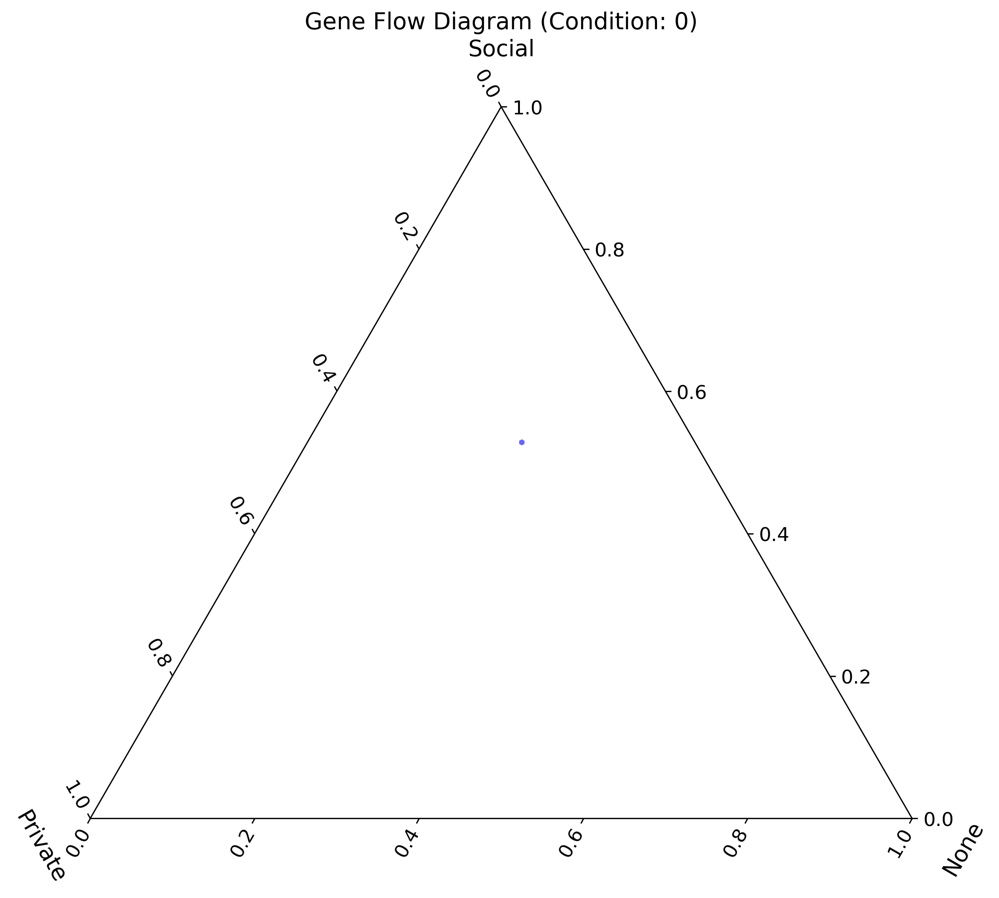

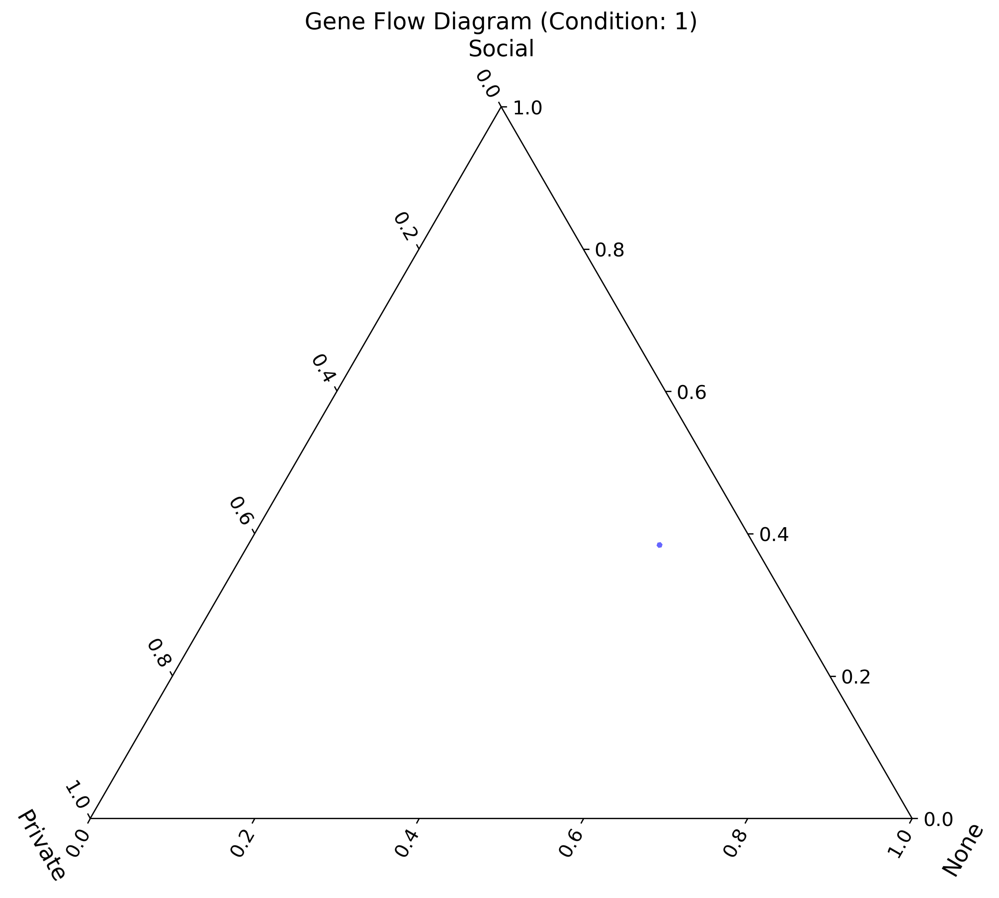

In [6]:
print("Preparing data for flow diagram...")
# Use a copy to avoid SettingWithCopyWarning
df_flow = df.copy()
genes_cols = ['gene_priv', 'gene_soc', 'gene_none']
probs = softmax(df_flow[genes_cols].values)
df_flow['prob_priv'] = probs[:, 0]
df_flow['prob_soc'] = probs[:, 1]
df_flow['prob_none'] = probs[:, 2]

# Aggregate by group and step
df_group_steps = df_flow.groupby(['run_id', 'group_id', 'step', 'close_target_index'])[['prob_priv', 'prob_soc', 'prob_none']].mean().reset_index()
df_group_steps = df_group_steps.sort_values(['run_id', 'group_id', 'step'])

# Calculate deltas
# Calculate deltas and smooth over multiple steps for robustness
window_size = 10_000
df_group_steps['d_priv'] = df_group_steps.groupby(['run_id', 'group_id'])['prob_priv'].diff()
df_group_steps['d_soc'] = df_group_steps.groupby(['run_id', 'group_id'])['prob_soc'].diff()
df_group_steps['d_none'] = df_group_steps.groupby(['run_id', 'group_id'])['prob_none'].diff()

# Rolling mean within each group to average changes over more steps
df_group_steps['d_priv'] = df_group_steps.groupby(['run_id', 'group_id'])['d_priv'].transform(lambda x: x.rolling(window_size, min_periods=1).mean())
df_group_steps['d_soc'] = df_group_steps.groupby(['run_id', 'group_id'])['d_soc'].transform(lambda x: x.rolling(window_size, min_periods=1).mean())
df_group_steps['d_none'] = df_group_steps.groupby(['run_id', 'group_id'])['d_none'].transform(lambda x: x.rolling(window_size, min_periods=1).mean())

# Drop NaNs from diff
df_group_steps = df_group_steps.dropna(subset=['d_priv'])

def plot_flow_diagram(df, condition_val, title):
    cond_df = df[df['close_target_index'] == condition_val].copy()
    if cond_df.empty:
        return
        
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(projection='ternary')
    
    # Binning the ternary space
    n_bins = 20
    bins = np.linspace(0, 1, n_bins + 1)
    
    # We'll use a simple grid binning on the probabilities
    # and then calculate mean vectors per bin
    cond_df.loc[:, 'bin_priv'] = pd.cut(cond_df['prob_priv'], bins=bins, labels=False)
    cond_df.loc[:, 'bin_soc'] = pd.cut(cond_df['prob_soc'], bins=bins, labels=False)
    
    binned = cond_df.groupby(['bin_priv', 'bin_soc']).agg({
        'prob_priv': 'mean',
        'prob_soc': 'mean',
        'prob_none': 'mean',
        'd_priv': 'mean',
        'd_soc': 'mean',
        'd_none': 'mean'
    }).reset_index().dropna()
    
    # Plot arrows
    # Order in mpltern: Top (t), Left (l), Right (r)
    # We'll map: Top=Social, Left=Private, Right=None
    ax.quiver(binned['prob_soc'], binned['prob_priv'], binned['prob_none'],
              binned['d_soc'], binned['d_priv'], binned['d_none'],
              color='blue', alpha=0.6, scale=0.5, units='xy')
    
    ax.set_tlabel("Social")
    ax.set_llabel("Private")
    ax.set_rlabel("None")
    ax.set_title(title)
    plt.show()

for cond in sorted(df_group_steps['close_target_index'].unique()):
    plot_flow_diagram(df_group_steps, cond, f"Gene Flow Diagram (Condition: {cond})")

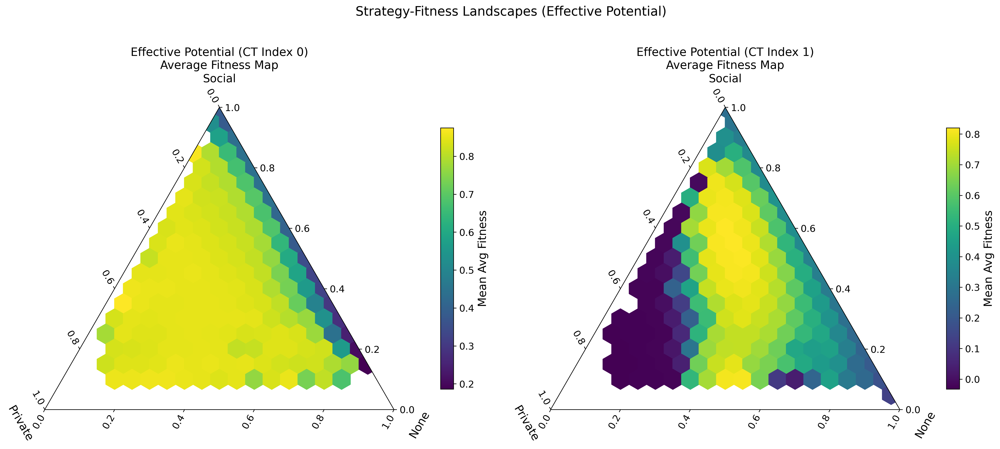

In [7]:
# 1. Visualize Effective Potential (Fitness Landscape)
# We average fitness scores across the strategy simplex
unique_indices = df['close_target_index'].unique()
n_indices = len(unique_indices)

fig = plt.figure(figsize=(9 * n_indices, 8))

for i, ct_idx in enumerate(unique_indices):
    ax = fig.add_subplot(1, n_indices, i + 1, projection='ternary')
    
    # Filter data for this condition
    subset = df[df['close_target_index'] == ct_idx]
    
    # Coordinates: t=Social, l=Private, r=None
    t = subset['p_soc']
    l = subset['p_priv']
    r = subset['p_none']
    v = subset['avg_fitness']
    
    # Use hexbin to compute mean fitness in each region
    # gridsize determines the resolution of the potential map
    hb = ax.hexbin(t, l, r, C=v, gridsize=20, cmap='viridis', reduce_C_function=np.mean)
    
    ax.set_tlabel("Social")
    ax.set_llabel("Private")
    ax.set_rlabel("None")
    ax.set_title(f"Effective Potential (CT Index {ct_idx})\nAverage Fitness Map")
    
    # Add colorbar for each facet
    cb = fig.colorbar(hb, ax=ax, shrink=0.6, pad=0.1)
    cb.set_label('Mean Avg Fitness')

plt.tight_layout()
plt.suptitle("Strategy-Fitness Landscapes (Effective Potential)", fontsize=16, y=1.05)
plt.show()

Calculating multi-step aggregate velocity for unified stream diagram...
Identifying trajectory clusters per condition...
Condition 1: Optimal clusters = 2 (Silhouette Score: 0.501)
Condition 0: Optimal clusters = 2 (Silhouette Score: 0.378)
Generating streamplot background...
Plotting clustered mean trajectories...


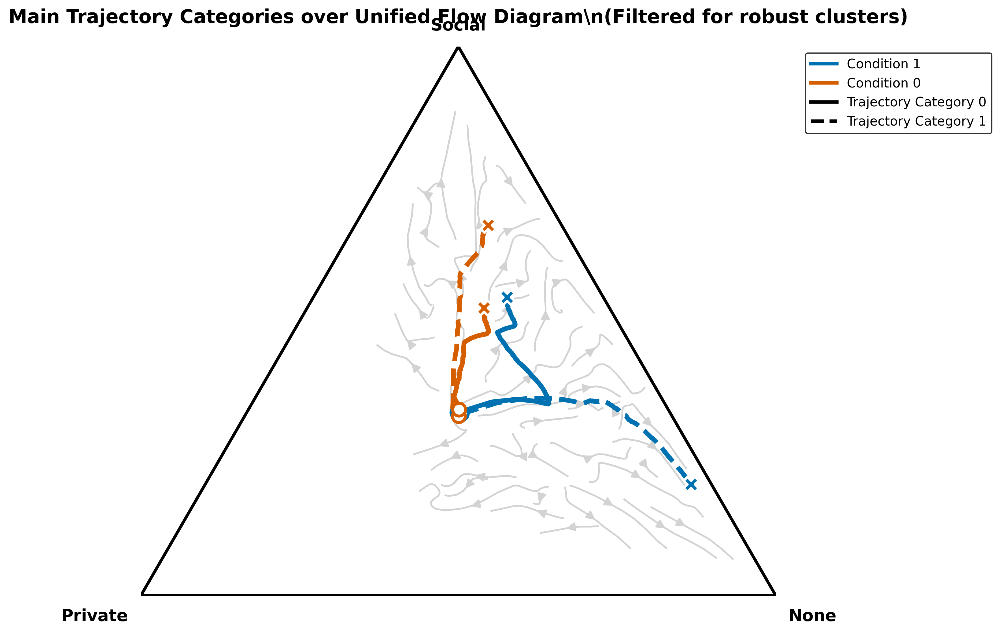

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from scipy.special import softmax
from scipy.interpolate import griddata
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from matplotlib.lines import Line2D
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)
# ==========================================
# 1. Prepare Probabilities (All Conditions)
# ==========================================
df_flow = df.copy()
genes_cols = ['gene_priv', 'gene_soc', 'gene_none']
probs = softmax(df_flow[genes_cols].values, axis=1)
df_flow['prob_priv'] = probs[:, 0]
df_flow['prob_soc'] = probs[:, 1]
df_flow['prob_none'] = probs[:, 2]
# Aggregate to group-level step data
df_group_steps = df_flow.groupby(['run_id', 'group_id', 'step', 'close_target_index'])[['prob_priv', 'prob_soc', 'prob_none']].mean().reset_index()
df_group_steps = df_group_steps.sort_values(['run_id', 'group_id', 'step'])
# ==========================================
# 2. Calculate Multi-Step Velocity
# ==========================================
print("Calculating multi-step aggregate velocity for unified stream diagram...")
smoothing_periods = 10 
df_group_steps['d_priv'] = df_group_steps.groupby(['run_id', 'group_id'])['prob_priv'].diff()
df_group_steps['d_soc'] = df_group_steps.groupby(['run_id', 'group_id'])['prob_soc'].diff()
df_group_steps['d_none'] = df_group_steps.groupby(['run_id', 'group_id'])['prob_none'].diff()
# Apply rolling mean to capture sustained velocity rather than instantaneous noise
for col in ['d_priv', 'd_soc', 'd_none']:
    df_group_steps[col] = df_group_steps.groupby(['run_id', 'group_id'])[col].transform(
        lambda x: x.rolling(smoothing_periods, min_periods=1).mean()
    )
df_clean = df_group_steps.dropna(subset=['d_priv']).copy()
# ==========================================
# 3. Transform Ternary to Cartesian 2D
# ==========================================
H = np.sqrt(3) / 2
# Empirical Positions
x = df_clean['prob_none'] + 0.5 * df_clean['prob_soc']
y = H * df_clean['prob_soc']
# Empirical Vectors
dx = df_clean['d_none'] + 0.5 * df_clean['d_soc']
dy = H * df_clean['d_soc']
# ==========================================
# 4. Interpolation & SMART DENSITY MASKING
# ==========================================
grid_res = 40 # Coarser grid for a cleaner streamplot
grid_x, grid_y = np.meshgrid(np.linspace(0, 1, grid_res), np.linspace(0, H, grid_res))
# Interpolate vectors
points = np.column_stack((x, y))
grid_dx = griddata(points, dx, (grid_x, grid_y), method='linear')
grid_dy = griddata(points, dy, (grid_x, grid_y), method='linear')
# --- THE SMART MASK ---
x_edges = np.linspace(0, 1, grid_res + 1)
y_edges = np.linspace(0, H, grid_res + 1)
counts, _, _ = np.histogram2d(x, y, bins=[x_edges, y_edges])
counts = counts.T 
# Since the grid is coarser, each bin covers more area
density_threshold = 5 
low_data_mask = counts < density_threshold
outside_triangle = (grid_y < 0) | (grid_y > np.sqrt(3) * grid_x) | (grid_y > np.sqrt(3) * (1 - grid_x))
combined_mask = low_data_mask | outside_triangle
# Use masked arrays instead of NaNs for better streamplot compatibility
grid_dx = np.ma.masked_where(combined_mask, grid_dx)
grid_dy = np.ma.masked_where(combined_mask, grid_dy)
# ==========================================
# 5. Robust Clustering per Condition
# ==========================================
print("Identifying trajectory clusters per condition...")
clustered_dfs = []
min_cluster_pct = 0.05 
conditions = df_group_steps['close_target_index'].unique()
for cond in conditions:
    cond_df = df_group_steps[df_group_steps['close_target_index'] == cond].copy()
    
    # Extract spatial summary features for each trajectory
    traj_features = cond_df.groupby(['run_id', 'group_id']).agg({
        'prob_soc': ['mean', 'last'],
        'prob_priv': ['mean', 'last']
    }).reset_index()
    traj_features.columns = ['run_id', 'group_id', 'soc_mean', 'soc_last', 'priv_mean', 'priv_last']
    X = traj_features[['soc_mean', 'soc_last', 'priv_mean', 'priv_last']].values
    
    # Find optimal k
    best_k = 2
    best_score = -1
    for k in range(2, 6):
        if k >= len(X): break
        kmeans = KMeans(n_clusters=k, random_state=42)
        labels = kmeans.fit_predict(X)
        score = silhouette_score(X, labels)
        if score > best_score:
            best_score = score
            best_k = k
            
    print(f"Condition {cond}: Optimal clusters = {best_k} (Silhouette Score: {best_score:.3f})")
    kmeans = KMeans(n_clusters=best_k, random_state=42)
    traj_features['trajectory_class'] = kmeans.fit_predict(X)
    
    # Filter out clusters that are too small
    total_runs = len(traj_features)
    class_counts = traj_features['trajectory_class'].value_counts()
    valid_classes = class_counts[class_counts / total_runs >= min_cluster_pct].index
    
    traj_features = traj_features[traj_features['trajectory_class'].isin(valid_classes)]
    
    # Merge back
    class_mapping = traj_features[['run_id', 'group_id', 'trajectory_class']]
    cond_df = cond_df.merge(class_mapping, on=['run_id', 'group_id'])
    clustered_dfs.append(cond_df)
# Recombine
df_group_steps_clustered = pd.concat(clustered_dfs, ignore_index=True)
# ==========================================
# 6. Visualization Setup
# ==========================================
fig, ax = plt.subplots(figsize=(11, 9))
plt.rcParams.update({'font.size': 12})
print("Generating streamplot background...")
strm = ax.streamplot(grid_x, grid_y, grid_dx, grid_dy, 
                     color='lightgray', linewidth=1.5, 
                     density=1.2, arrowsize=1.5, zorder=1)
print("Plotting clustered mean trajectories...")
colors = {conditions[0]: '#0072B2', conditions[1]: '#D55E00'} # Blue & Vermillion
linestyles = ['-', '--', ':', '-.']
# We need to build the legend dynamically
legend_elements = [
    Line2D([0], [0], color=colors[conditions[0]], lw=3, label=f'Condition {conditions[0]}'),
    Line2D([0], [0], color=colors[conditions[1]], lw=3, label=f'Condition {conditions[1]}')
]
for cond in conditions:
    cond_subset = df_group_steps_clustered[df_group_steps_clustered['close_target_index'] == cond]
    classes = cond_subset['trajectory_class'].unique()
    
    for i, class_id in enumerate(sorted(classes)):
        subset = cond_subset[cond_subset['trajectory_class'] == class_id]
        if subset.empty:
            continue
            
        mean_traj = subset.groupby('step')[['prob_priv', 'prob_soc', 'prob_none']].mean().reset_index().sort_values('step')
        
        mx = mean_traj['prob_none'] + 0.5 * mean_traj['prob_soc']
        my = H * mean_traj['prob_soc']
        
        ls = linestyles[i % len(linestyles)]
        ax.plot(mx, my, color=colors[cond], linestyle=ls, 
                linewidth=4, zorder=5, solid_capstyle='round')
        
        # Start and End points
        ax.scatter(mx.iloc[0], my.iloc[0], color='white', edgecolor=colors[cond], marker='o', s=120, linewidth=2.5, zorder=6)
        ax.scatter(mx.iloc[-1], my.iloc[-1], color=colors[cond], edgecolor='white', marker='X', s=160, linewidth=2, zorder=6)
# Create linestyle legend (we assume max classes per condition is 4 based on linestyles)
max_classes = df_group_steps_clustered.groupby('close_target_index')['trajectory_class'].nunique().max()
for i in range(max_classes):
    ls = linestyles[i % len(linestyles)]
    legend_elements.append(Line2D([0], [0], color='black', lw=3, linestyle=ls, label=f'Trajectory Category {i}'))
# Draw the Triangle Boundaries
triangle = Polygon([[0, 0], [1, 0], [0.5, H]], fill=False, edgecolor='black', linewidth=2.5, zorder=4)
ax.add_patch(triangle)
# Add Labels
ax.text(0.5, H + 0.02, "Social", ha='center', va='bottom', fontsize=14, weight='bold')
ax.text(-0.02, -0.02, "Private", ha='right', va='top', fontsize=14, weight='bold')
ax.text(1.02, -0.02, "None", ha='left', va='top', fontsize=14, weight='bold')
# Formatting
ax.axis('off')
ax.set_aspect('equal')
plt.title("Main Trajectory Categories over Unified Flow Diagram\\n(Filtered for robust clusters)", fontsize=16, weight='bold', pad=20)
ax.legend(handles=legend_elements, loc='upper right', frameon=True, edgecolor='black', bbox_to_anchor=(1.35, 1))
plt.tight_layout()
plt.show()

Identifying trajectory clusters per condition...
Condition 1: Optimal clusters = 3 (Silhouette Score: 0.438)
Condition 0: Optimal clusters = 3 (Silhouette Score: 0.399)
Plotting clustered trajectories...


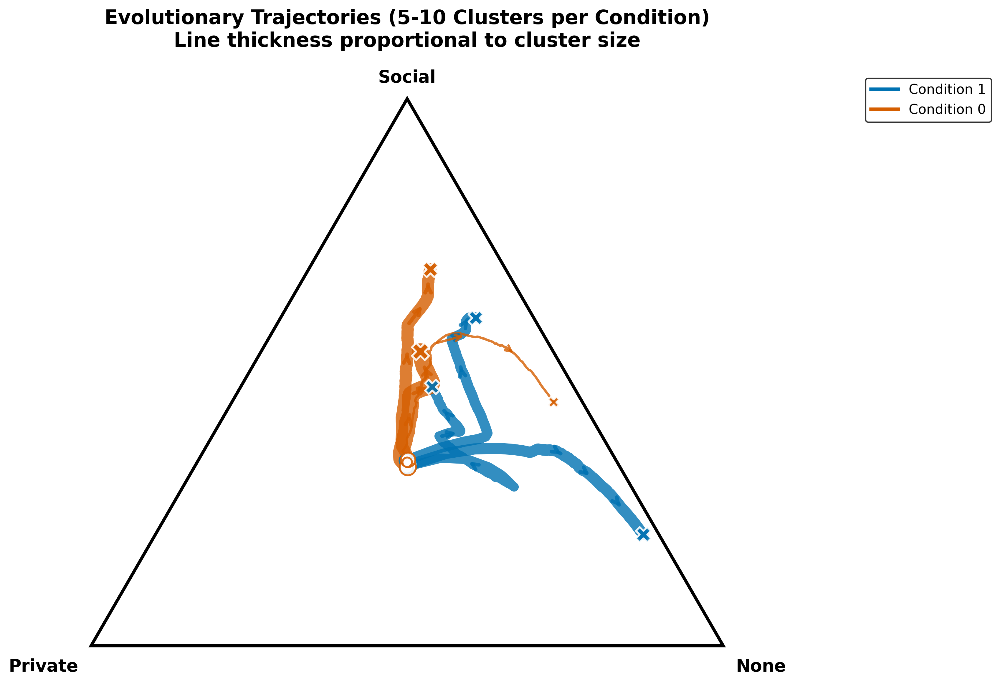

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from scipy.special import softmax
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from matplotlib.lines import Line2D
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)

# ==========================================
# 1. Prepare Probabilities (All Conditions)
# ==========================================
max_step = 199_999
df_flow = df[df.step < max_step].copy()
genes_cols = ['gene_priv', 'gene_soc', 'gene_none']
probs = softmax(df_flow[genes_cols].values, axis=1)

df_flow['prob_priv'] = probs[:, 0]
df_flow['prob_soc'] = probs[:, 1]
df_flow['prob_none'] = probs[:, 2]

# Aggregate to group-level step data
df_group_steps = df_flow.groupby(['run_id', 'group_id', 'step', 'close_target_index'])[['prob_priv', 'prob_soc', 'prob_none']].mean().reset_index()
df_group_steps = df_group_steps.sort_values(['run_id', 'group_id', 'step'])

# ==========================================
# 2. Robust Clustering per Condition (5-10 Clusters)
# ==========================================
print("Identifying trajectory clusters per condition...")

clustered_dfs = []
conditions = df_group_steps['close_target_index'].unique()

for cond in conditions:
    cond_df = df_group_steps[df_group_steps['close_target_index'] == cond].copy()
    
    # Extract spatial summary features for each trajectory
    traj_features = cond_df.groupby(['run_id', 'group_id']).agg({
        'prob_soc': ['mean', 'last'],
        'prob_priv': ['mean', 'last']
    }).reset_index()
    traj_features.columns = ['run_id', 'group_id', 'soc_mean', 'soc_last', 'priv_mean', 'priv_last']
    X = traj_features[['soc_mean', 'soc_last', 'priv_mean', 'priv_last']].values
    
    # Find optimal k between 5 and 10
    best_k = 5
    best_score = -1
    for k in range(3, 21):
        if k >= len(X): break
        kmeans = KMeans(n_clusters=k, random_state=42)
        labels = kmeans.fit_predict(X)
        score = silhouette_score(X, labels)
        if score > best_score:
            best_score = score
            best_k = k
            
    print(f"Condition {cond}: Optimal clusters = {best_k} (Silhouette Score: {best_score:.3f})")
    kmeans = KMeans(n_clusters=best_k, random_state=42)
    traj_features['trajectory_class'] = kmeans.fit_predict(X)
    
    # Calculate proportion of runs in each cluster
    total_runs = len(traj_features)
    class_counts = traj_features['trajectory_class'].value_counts()
    
    # Create a mapping for proportion
    proportion_map = (class_counts / total_runs).to_dict()
    traj_features['proportion'] = traj_features['trajectory_class'].map(proportion_map)
    
    # Merge back
    class_mapping = traj_features[['run_id', 'group_id', 'trajectory_class', 'proportion']]
    cond_df = cond_df.merge(class_mapping, on=['run_id', 'group_id'])
    clustered_dfs.append(cond_df)

# Recombine
df_group_steps_clustered = pd.concat(clustered_dfs, ignore_index=True)

# ==========================================
# 3. Visualization Setup
# ==========================================
H = np.sqrt(3) / 2
fig = plt.figure(figsize=(11, 9))
ax = fig.add_subplot(111)
plt.rcParams.update({'font.size': 12})

print("Plotting clustered trajectories...")
colors = {conditions[0]: '#0072B2', conditions[1]: '#D55E00'} # Blue & Vermillion

# We need to build the legend dynamically
legend_elements = [
    Line2D([0], [0], color=colors[conditions[0]], lw=3, label=f'Condition {conditions[0]}'),
    Line2D([0], [0], color=colors[conditions[1]], lw=3, label=f'Condition {conditions[1]}')
]

for cond in conditions:
    cond_subset = df_group_steps_clustered[df_group_steps_clustered['close_target_index'] == cond]
    classes = cond_subset['trajectory_class'].unique()
    
    for class_id in sorted(classes):
        subset = cond_subset[cond_subset['trajectory_class'] == class_id]
        if subset.empty:
            continue
            
        mean_traj = subset.groupby('step')[['prob_priv', 'prob_soc', 'prob_none']].mean().reset_index().sort_values('step')
        
        mx = mean_traj['prob_none'] + 0.5 * mean_traj['prob_soc']
        my = H * mean_traj['prob_soc']
        
        proportion = subset['proportion'].iloc[0]
        # Calculate line thickness based on proportion (min 1, max 20)
        lw = max(1.0, proportion * 25)
        
        # Draw thick line for the trajectory
        line, = ax.plot(mx, my, color=colors[cond], linestyle='-', alpha=0.8, 
                linewidth=lw, zorder=5, solid_capstyle='round')
        
        # Add arrows along the trajectory to indicate flow
        num_arrows = 3
        if len(mx) > 2:
            arrow_indices = np.linspace(0, len(mx)-1, num_arrows+2, dtype=int)[1:-1]
            look_ahead = max(1, len(mx) // 20)
            
            for idx in arrow_indices:
                idx_next = min(len(mx)-1, idx + look_ahead)
                ax.annotate('', xy=(mx.iloc[idx_next], my.iloc[idx_next]), 
                            xytext=(mx.iloc[idx], my.iloc[idx]),
                            arrowprops=dict(arrowstyle="->", color=colors[cond], lw=min(3, lw), alpha=0.8),
                            zorder=6)
        
        # Start and End markers (sized proportionally as well)
        ax.scatter(mx.iloc[0], my.iloc[0], color='white', edgecolor=colors[cond], marker='o', s=40 + lw*10, linewidth=1.5, zorder=7, alpha=0.9)
        ax.scatter(mx.iloc[-1], my.iloc[-1], color=colors[cond], edgecolor='white', marker='X', s=60 + lw*10, linewidth=1.5, zorder=7, alpha=0.9)

# Draw the Triangle Boundaries
triangle = Polygon([[0, 0], [1, 0], [0.5, H]], fill=False, edgecolor='black', linewidth=2.5, zorder=4)
ax.add_patch(triangle)

# Add Labels
ax.text(0.5, H + 0.02, "Social", ha='center', va='bottom', fontsize=14, weight='bold')
ax.text(-0.02, -0.02, "Private", ha='right', va='top', fontsize=14, weight='bold')
ax.text(1.02, -0.02, "None", ha='left', va='top', fontsize=14, weight='bold')

# Formatting
ax.axis('off')
ax.set_aspect('equal')
plt.title("Evolutionary Trajectories (5-10 Clusters per Condition)\nLine thickness proportional to cluster size", fontsize=16, weight='bold', pad=20)

ax.legend(handles=legend_elements, loc='upper right', frameon=True, edgecolor='black', bbox_to_anchor=(1.35, 1))

plt.tight_layout()
plt.show()

## Major Agents Trajectories
Here we visualize the trajectories of the longest-lived agents individually (not aggregated by groups), colored by the simulation step.

Plotting individual trajectories for major agents...


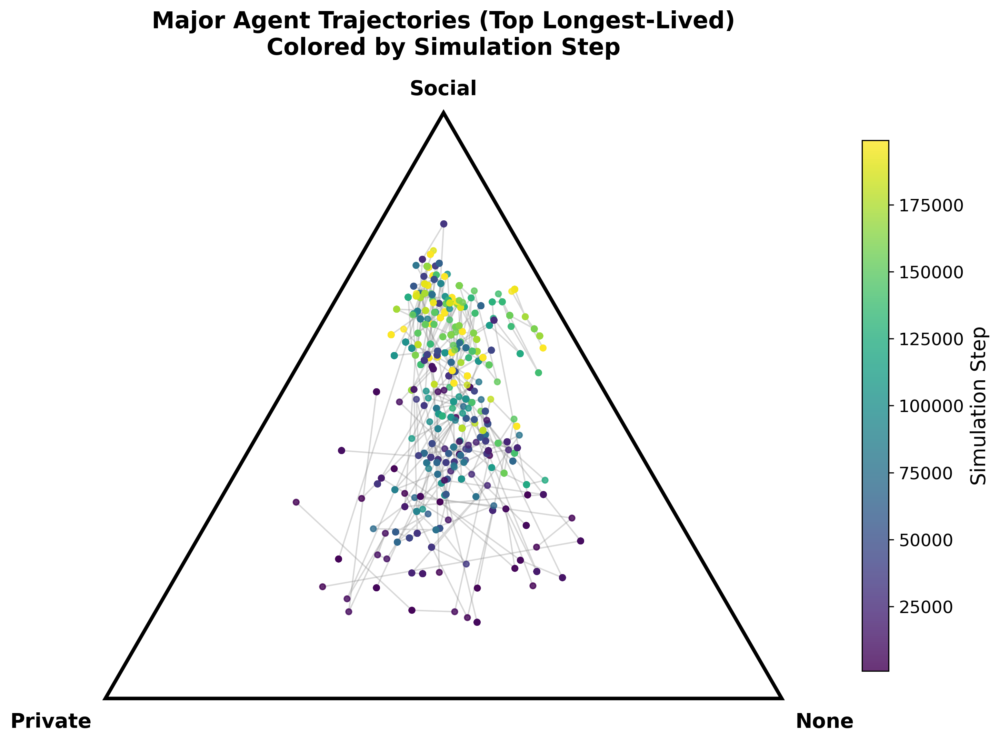

In [10]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors

print("Plotting individual trajectories for major agents...")

# Select the top 20 agents that lived the longest
top_agents = df_flow.groupby(['run_id', 'group_id', 'agent_id']).agg({'age': 'max'}).nlargest(20, 'age').index

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111)
plt.rcParams.update({'font.size': 12})
H = np.sqrt(3) / 2

# Draw the Triangle Boundaries
triangle = Polygon([[0, 0], [1, 0], [0.5, H]], fill=False, edgecolor='black', linewidth=2.5, zorder=4)
ax.add_patch(triangle)

cmap = cm.viridis
norm = mcolors.Normalize(vmin=df_flow['step'].min(), vmax=df_flow['step'].max())

for run, group, agent in top_agents:
    subset = df_flow[(df_flow['run_id'] == run) & (df_flow['group_id'] == group) & (df_flow['agent_id'] == agent)].sort_values('step')
    if subset.empty:
        continue
    
    mx = subset['prob_none'] + 0.5 * subset['prob_soc']
    my = H * subset['prob_soc']
    
    # Plot the path with a thin line
    ax.plot(mx, my, color='gray', alpha=0.3, linewidth=1, zorder=1)
    
    # Scatter points colored by step
    sc = ax.scatter(mx, my, c=subset['step'], cmap=cmap, norm=norm, s=15, zorder=2, alpha=0.8)

# Add Labels
ax.text(0.5, H + 0.02, "Social", ha='center', va='bottom', fontsize=14, weight='bold')
ax.text(-0.02, -0.02, "Private", ha='right', va='top', fontsize=14, weight='bold')
ax.text(1.02, -0.02, "None", ha='left', va='top', fontsize=14, weight='bold')

# Formatting
ax.axis('off')
ax.set_aspect('equal')
plt.title("Major Agent Trajectories (Top Longest-Lived)\nColored by Simulation Step", fontsize=16, weight='bold', pad=20)
plt.colorbar(sc, label='Simulation Step', shrink=0.7)

plt.tight_layout()
plt.show()


## Agent Trajectories (Flow of the Majority)
Here we visualize the trajectories of a large representative sample of agents to show the general evolutionary flow without aggregating by groups. The color indicates the simulation step.

## Agent Trajectories Streamplot
Here we visualize the evolutionary flow of the agents as a streamplot. The vector field is computed from the step-to-step movement of a representative sample of agents, and the streamlines are colored by the average simulation step in that region.

## Agent Trajectories Streamplot
Here we visualize the evolutionary flow of the agents as a streamplot. The vector field is computed from the step-to-step movement of a representative sample of agents. Regions with sparse data are masked out to show only dominant paths.

Calculating vector field for streamplot...


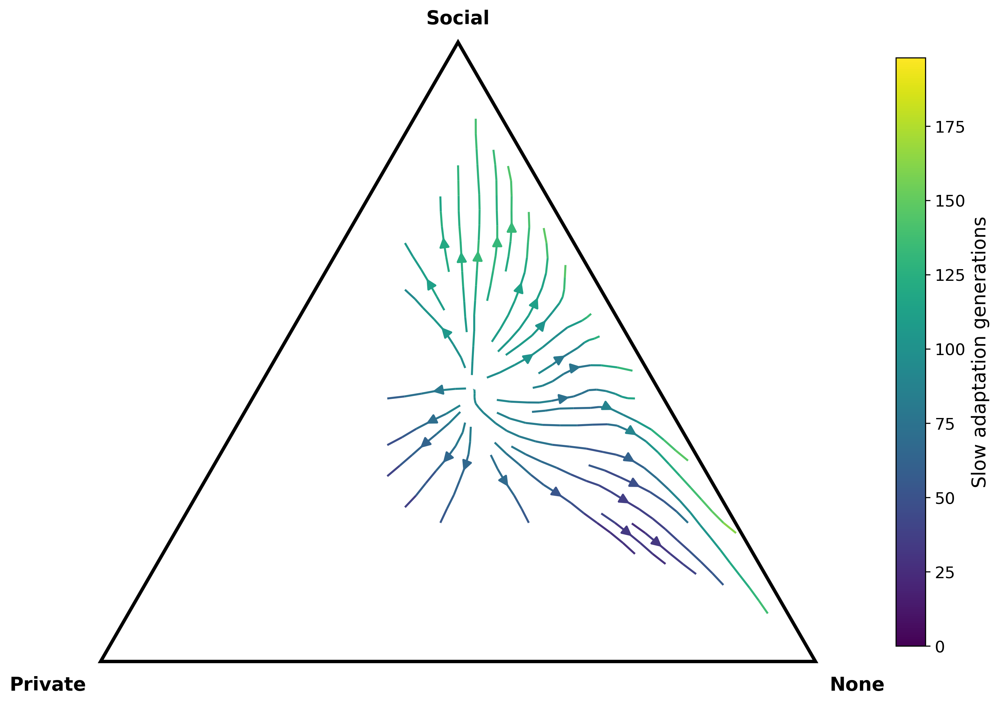

In [11]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import numpy.ma as ma
from scipy.stats import binned_statistic_2d

print("Calculating vector field for streamplot...")

# Use a sample of agents for calculating the flow to keep it fast
unique_agents = df_flow[['run_id', 'group_id', 'agent_id']].drop_duplicates()
n_samples = len(unique_agents) # min(5000, len(unique_agents))
sampled_agents = unique_agents.sample(n=n_samples, random_state=42)
df_sample = df_flow.merge(sampled_agents, on=['run_id', 'group_id', 'agent_id']).sort_values(['run_id', 'group_id', 'agent_id', 'step'])
df_sample['step'] -= 999
df_sample['step'] /= 1000

H = np.sqrt(3) / 2
df_sample['mx'] = df_sample['prob_none'] + 0.5 * df_sample['prob_soc']
df_sample['my'] = H * df_sample['prob_soc']

# Calculate the movement vectors (dmx, dmy)
df_sample['dmx'] = df_sample.groupby(['run_id', 'group_id', 'agent_id'])['mx'].diff()
df_sample['dmy'] = df_sample.groupby(['run_id', 'group_id', 'agent_id'])['my'].diff()
df_diff = df_sample.dropna(subset=['dmx', 'dmy'])

# Create a grid over the simplex
grid_res = 100
x_bins = np.linspace(-0.05, 1.05, grid_res)
y_bins = np.linspace(-0.05, H + 0.05, grid_res)
X, Y = np.meshgrid(x_bins[:-1] + np.diff(x_bins)/2, y_bins[:-1] + np.diff(y_bins)/2)

# Bin the data
U, _, _, _ = binned_statistic_2d(df_diff['mx'], df_diff['my'], df_diff['dmx'], statistic='mean', bins=[x_bins, y_bins])
V, _, _, _ = binned_statistic_2d(df_diff['mx'], df_diff['my'], df_diff['dmy'], statistic='mean', bins=[x_bins, y_bins])
C, _, _, _ = binned_statistic_2d(df_diff['mx'], df_diff['my'], df_diff['step'], statistic='mean', bins=[x_bins, y_bins])
Counts, _, _, _ = binned_statistic_2d(df_diff['mx'], df_diff['my'], df_diff['dmx'], statistic='count', bins=[x_bins, y_bins])

# Transpose because binned_statistic_2d returns (nx, ny) but we need (ny, nx) for streamplot
U = U.T
V = V.T
C = C.T
Counts = Counts.T

# Mask cells with sparse data (e.g., less than 20 points)
# This elegantly removes streamlines where there is not enough data,
# and completely stops streamlines from entering areas outside the triangle (where count is 0)
min_data_points = 500
mask = Counts < min_data_points

U_masked = ma.array(U, mask=mask)
V_masked = ma.array(V, mask=mask)
C_masked = ma.array(C, mask=mask)

# Now Plot
fig = plt.figure(figsize=(11, 9))
ax = fig.add_subplot(111)
plt.rcParams.update({'font.size': 12})

# Draw the Triangle Boundaries
triangle = Polygon([[0, 0], [1, 0], [0.5, H]], fill=False, edgecolor='black', linewidth=2.5, zorder=4)
ax.add_patch(triangle)

cmap = cm.viridis
norm = mcolors.Normalize(vmin=df_sample['step'].min(), vmax=df_sample['step'].max())

# Create the streamplot
strm = ax.streamplot(X, Y, U_masked, V_masked, color=C_masked, cmap=cmap, norm=norm, 
                     linewidth=1.5, density=1.5, arrowsize=1.5, zorder=2)

# Add Labels
ax.text(0.5, H + 0.02, "Social", ha='center', va='bottom', fontsize=14, weight='bold')
ax.text(-0.02, -0.02, "Private", ha='right', va='top', fontsize=14, weight='bold')
ax.text(1.02, -0.02, "None", ha='left', va='top', fontsize=14, weight='bold')

# Formatting
ax.axis('off')
ax.set_aspect('equal')
# plt.title("Agent Trajectories Streamplot\nColored by Average Simulation Step", fontsize=16, weight='bold', pad=20)
cbar = plt.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.7)
cbar.set_label('Slow adaptation generations')

plt.tight_layout()
plt.show()


## Agent Trajectories (Flow of the Majority)
Here we visualize the evolutionary flow by plotting the actual trajectory lines of a representative sample of agents. By using a LineCollection, every segment of movement is accurately colored by the exact simulation step it occurred, eliminating mathematical artifacts (where time appears to flow backward) caused by averaging a dynamic vector field.

## Direction of Selection (All Agents Streamplot)
Because agents in a Steady State Genetic Algorithm (SSGA) are constantly replaced in their array slots, tracking individual 'slots' over time creates false vectors from random mutations and replacements.

Instead, we visualize the **true direction of selection** by looking at the entire population density across time. We compute the average simulation step at which agents are found in each region of the simplex. The gradient of this 'time field' explicitly gives the direction of evolution—streamlines naturally flow from regions explored early to regions occupied late. We use all agents, without aggregation.

## Direction of Selection with Dominant Trajectories
Visualizes the overall direction of selection across all agents, with the dominant condition-specific evolutionary trajectories overlaid on top.

## Direction of Selection with Dominant Trajectories (Per Condition)
Visualizes the overall direction of selection across all agents for each initialization condition, with the condition-specific dominant evolutionary trajectories overlaid on top.

Calculating direction of selection for each condition...


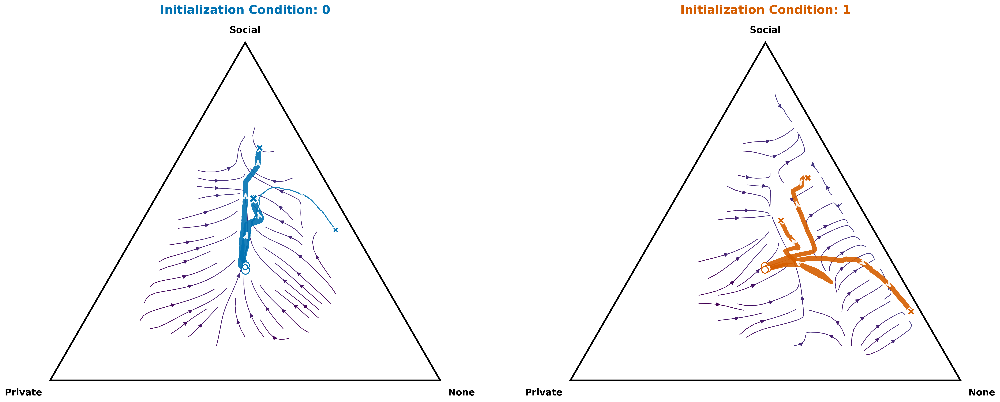

In [12]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import numpy.ma as ma
from scipy.stats import binned_statistic_2d
from scipy.ndimage import gaussian_filter
from matplotlib.patches import Polygon
from matplotlib.lines import Line2D

print("Calculating direction of selection for each condition...")

conditions = df_flow['close_target_index'].unique()[:2]
colors_cond = {conditions[0]: '#0072B2', conditions[1]: '#D55E00'}
H = np.sqrt(3) / 2
grid_res = 50
x_bins = np.linspace(-0.05, 1.05, grid_res)
y_bins = np.linspace(-0.05, H + 0.05, grid_res)
X, Y = np.meshgrid(x_bins[:-1] + np.diff(x_bins)/2, y_bins[:-1] + np.diff(y_bins)/2)

fig, axes = plt.subplots(1, 2, figsize=(22, 9))
plt.rcParams.update({'font.size': 12})

cmap = cm.viridis
norm = mcolors.Normalize(vmin=df_flow['step'].min(), vmax=df_flow['step'].max())
max_step = 49_999

for i, cond in enumerate(conditions):
    ax = axes[i]
    
    # Filter data for this condition
    df_cond = df_flow[df_flow['close_target_index'] == cond]
    df_cond = df_cond[df_cond.step < max_step]
    mx = df_cond['prob_none'] + 0.5 * df_cond['prob_soc']
    my = H * df_cond['prob_soc']
    step = df_cond['step']
    
    # Bin the data
    C, _, _, _ = binned_statistic_2d(mx, my, step, statistic='mean', bins=[x_bins, y_bins])
    Counts, _, _, _ = binned_statistic_2d(mx, my, step, statistic='count', bins=[x_bins, y_bins])
    C = C.T
    Counts = Counts.T
    
    # Smooth time field and calculate gradient
    C_filled = np.where(np.isnan(C), np.nanmean(C), C)
    C_smooth = gaussian_filter(C_filled, sigma=1.5)
    dC_dy, dC_dx = np.gradient(C_smooth)
    
    # Mask cells with sparse data
    min_data_points = 25
    mask = Counts < min_data_points
    U_masked = ma.array(dC_dx, mask=mask)
    V_masked = ma.array(dC_dy, mask=mask)
    C_masked = ma.array(C, mask=mask)
    
    # Draw Boundaries
    triangle = Polygon([[0, 0], [1, 0], [0.5, H]], fill=False, edgecolor='black', linewidth=2.5, zorder=4)
    ax.add_patch(triangle)
    
    # Streamplot
    strm = ax.streamplot(X, Y, U_masked, V_masked, color=C_masked, cmap=cmap, norm=norm, 
                         linewidth=1.0, density=1.5, arrowsize=1.2, zorder=2)
    
    # Overlay Dominant Trajectories for this condition
    if 'df_group_steps_clustered' in locals() or 'df_group_steps_clustered' in globals():
        cond_subset = df_group_steps_clustered[df_group_steps_clustered['close_target_index'] == cond]
        classes = cond_subset['trajectory_class'].unique()
        for class_id in sorted(classes):
            subset = cond_subset[cond_subset['trajectory_class'] == class_id]
            if subset.empty: continue
            
            mean_traj = subset.groupby('step')[['prob_priv', 'prob_soc', 'prob_none']].mean().reset_index().sort_values('step')
            tmx = mean_traj['prob_none'] + 0.5 * mean_traj['prob_soc']
            tmy = H * mean_traj['prob_soc']
            proportion = subset['proportion'].iloc[0]
            lw = max(1.5, proportion * 20)
            
            # Draw trajectory line
            ax.plot(tmx, tmy, color=colors_cond[cond], linestyle='-', alpha=0.9, linewidth=lw, zorder=5, solid_capstyle='round')
            
            # Add arrows
            if len(tmx) > 2:
                arrow_indices = np.linspace(0, len(tmx)-1, 4, dtype=int)[1:-1]
                look_ahead = max(1, len(tmx) // 20)
                for idx in arrow_indices:
                    idx_next = min(len(tmx)-1, idx + look_ahead)
                    ax.annotate('', xy=(tmx.iloc[idx_next], tmy.iloc[idx_next]), 
                                xytext=(tmx.iloc[idx], tmy.iloc[idx]),
                                arrowprops=dict(arrowstyle="->", color='white', lw=min(3, lw), alpha=0.9),
                                zorder=6)
            
            # Start/End markers
            ax.scatter(tmx.iloc[0], tmy.iloc[0], color='white', edgecolor=colors_cond[cond], marker='o', s=40 + lw*10, linewidth=1.5, zorder=7, alpha=1.0)
            ax.scatter(tmx.iloc[-1], tmy.iloc[-1], color=colors_cond[cond], edgecolor='white', marker='X', s=60 + lw*10, linewidth=1.5, zorder=7, alpha=1.0)
    
    # Add Labels & Formatting
    ax.text(0.5, H + 0.02, "Social", ha='center', va='bottom', fontsize=14, weight='bold')
    ax.text(-0.02, -0.02, "Private", ha='right', va='top', fontsize=14, weight='bold')
    ax.text(1.02, -0.02, "None", ha='left', va='top', fontsize=14, weight='bold')
    ax.axis('off')
    ax.set_aspect('equal')
    ax.set_title(f"Initialization Condition: {cond}", fontsize=18, weight='bold', pad=20, color=colors_cond[cond])

# fig.suptitle("Direction of Selection with Dominant Trajectories", fontsize=22, weight='bold', y=0.95)
# cbar = plt.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes.ravel().tolist(), shrink=0.7, pad=0.02)
# cbar.set_label('Average Simulation Step', fontsize=14)

plt.tight_layout()
plt.subplots_adjust(top=0.88)
plt.show()


## Evolutionary Divergence Over Time
This section tracks how the expression of the three strategies (Private, Social, None) changes over the simulation steps, comparing the different initialization conditions. The solid lines represent the mean probability across all runs and groups, while the shaded areas represent the standard deviation.

Calculating strategy evolution over time...


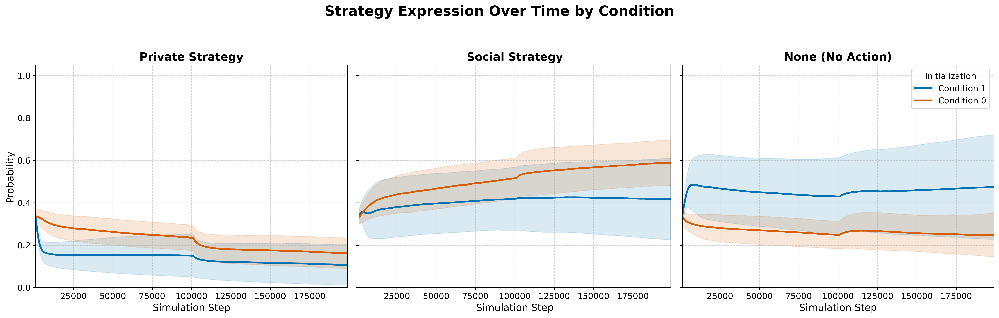

In [13]:
import matplotlib.pyplot as plt
import numpy as np

print("Calculating strategy evolution over time...")

conditions = df_group_steps['close_target_index'].unique()[:2]
colors_cond = {conditions[0]: '#0072B2', conditions[1]: '#D55E00'}

# Calculate mean and std over runs and groups for each step and condition
agg_time = df_group_steps.groupby(['step', 'close_target_index'])[['prob_priv', 'prob_soc', 'prob_none']].agg(['mean', 'std']).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)
plt.rcParams.update({'font.size': 12})

strategies = ['prob_priv', 'prob_soc', 'prob_none']
titles = ['Private Strategy', 'Social Strategy', 'None (No Action)']

for i, (strat, title) in enumerate(zip(strategies, titles)):
    ax = axes[i]
    
    for cond in conditions:
        # Extract data for this condition
        cond_data = agg_time[agg_time['close_target_index'] == cond]
        steps = cond_data['step']
        mean_val = cond_data[strat]['mean']
        std_val = cond_data[strat]['std']
        
        ax.plot(steps, mean_val, color=colors_cond[cond], label=f"Condition {cond}", linewidth=2.5)
        ax.fill_between(steps, mean_val - std_val, mean_val + std_val, color=colors_cond[cond], alpha=0.15)
        
    ax.set_title(title, fontsize=16, weight='bold')
    ax.set_xlabel("Simulation Step", fontsize=14)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.set_xlim(steps.min(), steps.max())
    ax.set_ylim(0, 1.05)

axes[0].set_ylabel("Probability", fontsize=14)
axes[2].legend(title="Initialization", loc='upper right', fontsize=12)

fig.suptitle("Strategy Expression Over Time by Condition", fontsize=20, weight='bold', y=1.05)
plt.tight_layout()
plt.show()


## Temporal Change in Evolutionary Gradient
To explicitly visualize how the direction of selection changes over time, we split the simulation into Early, Mid, and Late phases.

By calculating the step-to-step movement vectors of the **group means** (bypassing individual agent mutation/replacement noise), we can construct a true dynamic vector field for each time window. The streamlines show the evolutionary gradient at that specific phase, while their color intensity represents the population density in that region.

Calculating temporal evolutionary gradients...


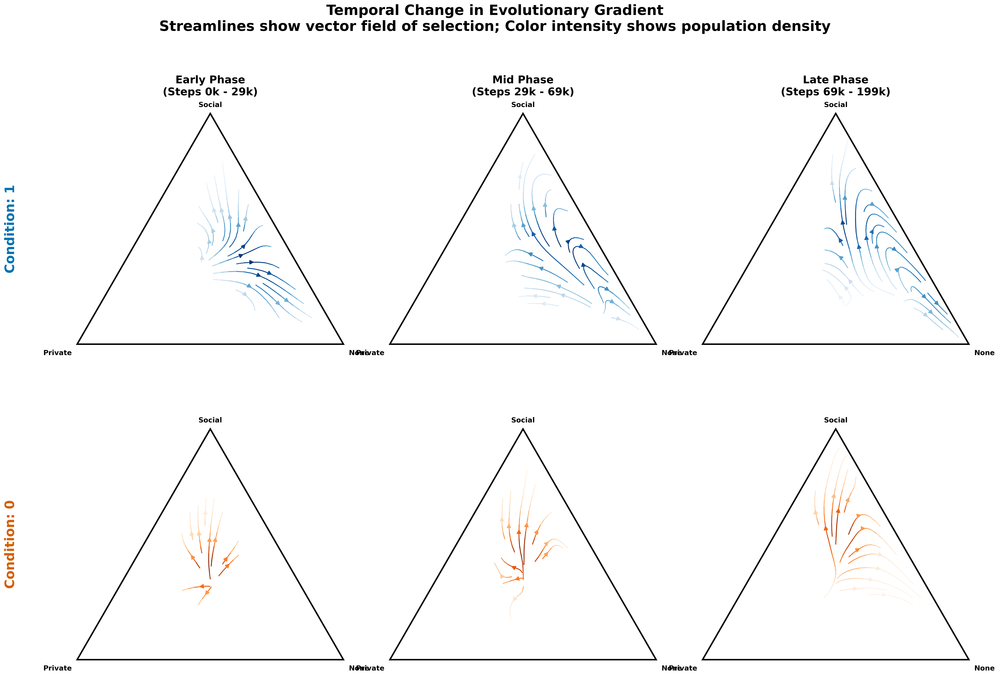

In [14]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import numpy.ma as ma
from scipy.stats import binned_statistic_2d
from scipy.ndimage import gaussian_filter
from matplotlib.patches import Polygon

print("Calculating temporal evolutionary gradients...")

# We use group-level mean trajectories to compute a clean evolutionary vector field
H = np.sqrt(3) / 2
df_gs = df_group_steps.copy()
df_gs['mx'] = df_gs['prob_none'] + 0.5 * df_gs['prob_soc']
df_gs['my'] = H * df_gs['prob_soc']

# Calculate robust movement vectors for each group
df_gs = df_gs.sort_values(['run_id', 'group_id', 'step'])
df_gs['dmx'] = df_gs.groupby(['run_id', 'group_id'])['mx'].diff()
df_gs['dmy'] = df_gs.groupby(['run_id', 'group_id'])['my'].diff()
df_gs = df_gs.dropna(subset=['dmx', 'dmy'])

# Define 3 time windows
max_step = df_gs['step'].max()
time_bins = [0, 29_999, 69_999, max_step + 1]
time_labels = ['Early', 'Mid', 'Late']

conditions = df_gs['close_target_index'].unique()[:2]
fig, axes = plt.subplots(2, 3, figsize=(24, 16))
plt.rcParams.update({'font.size': 12})

grid_res = 35  # Grid resolution for streamplot bins
x_bins = np.linspace(-0.05, 1.05, grid_res)
y_bins = np.linspace(-0.05, H + 0.05, grid_res)
X, Y = np.meshgrid(x_bins[:-1] + np.diff(x_bins)/2, y_bins[:-1] + np.diff(y_bins)/2)

# Colormaps for density
colors_cond = {conditions[0]: 'Blues', conditions[1]: 'Oranges'}
title_colors = {conditions[0]: '#0072B2', conditions[1]: '#D55E00'}

for row, cond in enumerate(conditions):
    cond_data = df_gs[df_gs['close_target_index'] == cond]
    
    for col, (t_start, t_end) in enumerate(zip(time_bins[:-1], time_bins[1:])):
        ax = axes[row, col]
        
        # Data for this condition and time window
        window_data = cond_data[(cond_data['step'] >= t_start) & (cond_data['step'] < t_end)]
        
        # Draw triangle
        triangle = Polygon([[0, 0], [1, 0], [0.5, H]], fill=False, edgecolor='black', linewidth=2.5, zorder=4)
        ax.add_patch(triangle)
        
        if len(window_data) < 50:
            ax.axis('off')
            ax.set_aspect('equal')
            continue
            
        # Bin vectors
        U, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmx'], statistic='mean', bins=[x_bins, y_bins])
        V, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmy'], statistic='mean', bins=[x_bins, y_bins])
        Counts, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmx'], statistic='count', bins=[x_bins, y_bins])
        
        U, V, Counts = U.T, V.T, Counts.T
        
        # Smooth vectors slightly to make streamplot fluid
        U_filled = np.nan_to_num(U, 0)
        V_filled = np.nan_to_num(V, 0)
        U_smooth = gaussian_filter(U_filled, sigma=1.0)
        V_smooth = gaussian_filter(V_filled, sigma=1.0)
        
        # Mask areas where the population isn't present during this time window
        mask = Counts < 5
        U_masked = ma.array(U_smooth, mask=mask)
        V_masked = ma.array(V_smooth, mask=mask)
        
        # Color by density (smoothed count)
        density = gaussian_filter(Counts, sigma=1.5)
        density_masked = ma.array(density, mask=mask)
        
        # Streamplot
        try:
            ax.streamplot(X, Y, U_masked, V_masked, color=density_masked, cmap=colors_cond[cond], 
                          linewidth=1.5, density=1.2, arrowsize=1.5, zorder=2)
        except ValueError:
            pass # Fallback if vector field is completely empty
            
        # Add Labels
        ax.text(0.5, H + 0.02, "Social", ha='center', va='bottom', fontsize=12, weight='bold')
        ax.text(-0.02, -0.02, "Private", ha='right', va='top', fontsize=12, weight='bold')
        ax.text(1.02, -0.02, "None", ha='left', va='top', fontsize=12, weight='bold')
        
        ax.axis('off')
        ax.set_aspect('equal')
        
        # Column Titles (Time Windows)
        if row == 0:
            ax.set_title(f"{time_labels[col]} Phase\n(Steps {int(t_start//1000)}k - {int(t_end//1000)}k)", fontsize=18, weight='bold', pad=15)
            
    # Row Labels (Conditions)
    axes[row, 0].text(-0.25, H/2, f"Condition: {cond}", rotation=90, va='center', ha='center', 
                      fontsize=22, weight='bold', color=title_colors[cond])

fig.suptitle("Temporal Change in Evolutionary Gradient\nStreamlines show vector field of selection; Color intensity shows population density", 
             fontsize=24, weight='bold', y=1.02)

plt.tight_layout()
plt.subplots_adjust(left=0.08, top=0.90, hspace=0.1, wspace=0.1)
plt.show()


## Temporal Evolutionary Flow with Dominant Trajectories
This adds the **dominant evolutionary trajectories** on top of the temporal streamplot grids.

To clearly show the progression through time:
- The trajectory segment occurring during the **active time phase** is drawn in solid, bold color.
- The trajectory segment from **previous phases** (history) is 'grayed out' to provide context for where the population came from, without distracting from the current flow.

Calculating temporal gradients and overlaying trajectories...


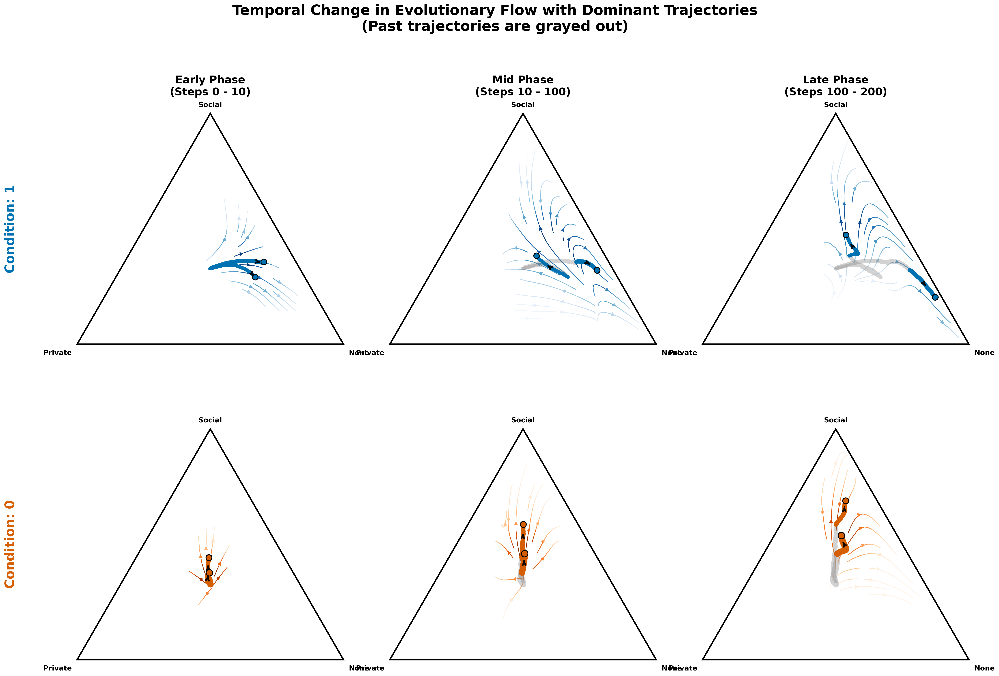

In [15]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import numpy.ma as ma
from scipy.stats import binned_statistic_2d
from scipy.ndimage import gaussian_filter
from matplotlib.patches import Polygon

print("Calculating temporal gradients and overlaying trajectories...")

H = np.sqrt(3) / 2
df_gs = df_group_steps.copy()
df_gs['mx'] = df_gs['prob_none'] + 0.5 * df_gs['prob_soc']
df_gs['my'] = H * df_gs['prob_soc']

df_gs = df_gs.sort_values(['run_id', 'group_id', 'step'])
df_gs['dmx'] = df_gs.groupby(['run_id', 'group_id'])['mx'].diff()
df_gs['dmy'] = df_gs.groupby(['run_id', 'group_id'])['my'].diff()
df_gs = df_gs.dropna(subset=['dmx', 'dmy'])

df_gs['step'] -= 999
df_gs['step'] /= 1000
max_step = df_gs['step'].max()
time_bins = [0, 10, 100, 200]
time_labels = ['Early', 'Mid', 'Late']

conditions = df_gs['close_target_index'].unique()[:2]
fig, axes = plt.subplots(2, 3, figsize=(24, 16))
plt.rcParams.update({'font.size': 12})

grid_res = 35
x_bins = np.linspace(-0.05, 1.05, grid_res)
y_bins = np.linspace(-0.05, H + 0.05, grid_res)
X, Y = np.meshgrid(x_bins[:-1] + np.diff(x_bins)/2, y_bins[:-1] + np.diff(y_bins)/2)

colors_cond = {conditions[0]: 'Blues', conditions[1]: 'Oranges'}
title_colors = {conditions[0]: '#0072B2', conditions[1]: '#D55E00'}

for row, cond in enumerate(conditions):
    cond_data = df_gs[df_gs['close_target_index'] == cond]
    
    for col, (t_start, t_end) in enumerate(zip(time_bins[:-1], time_bins[1:])):
        ax = axes[row, col]
        
        window_data = cond_data[(cond_data['step'] >= t_start) & (cond_data['step'] < t_end)]
        
        triangle = Polygon([[0, 0], [1, 0], [0.5, H]], fill=False, edgecolor='black', linewidth=2.5, zorder=4)
        ax.add_patch(triangle)
        
        if len(window_data) >= 50:
            U, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmx'], statistic='mean', bins=[x_bins, y_bins])
            V, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmy'], statistic='mean', bins=[x_bins, y_bins])
            Counts, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmx'], statistic='count', bins=[x_bins, y_bins])
            
            U, V, Counts = U.T, V.T, Counts.T
            
            U_smooth = gaussian_filter(np.nan_to_num(U, 0), sigma=1.0)
            V_smooth = gaussian_filter(np.nan_to_num(V, 0), sigma=1.0)
            
            mask = Counts < 5
            U_masked = ma.array(U_smooth, mask=mask)
            V_masked = ma.array(V_smooth, mask=mask)
            
            density = gaussian_filter(Counts, sigma=1.5)
            density_masked = ma.array(density, mask=mask)
            
            try:
                # Make streamplot transparent so trajectories pop out
                ax.streamplot(X, Y, U_masked, V_masked, color=density_masked, cmap=colors_cond[cond], 
                              linewidth=1.2, density=1.2, arrowsize=1.2, zorder=2)
            except ValueError:
                pass
                
        # ==========================================
        # Overlay Dominant Trajectories with Grayed History
        # ==========================================
        if 'df_group_steps_clustered' in locals() or 'df_group_steps_clustered' in globals():
            cond_subset = df_group_steps_clustered[df_group_steps_clustered['close_target_index'] == cond]
            classes = cond_subset['trajectory_class'].unique()[:2]
            for class_id in sorted(classes):
                subset = cond_subset[cond_subset['trajectory_class'] == class_id]
                if subset.empty: continue
                
                mean_traj = subset.groupby('step')[['prob_priv', 'prob_soc', 'prob_none']].mean().reset_index().sort_values('step')
                tmx = mean_traj['prob_none'] + 0.5 * mean_traj['prob_soc']
                tmy = H * mean_traj['prob_soc']
                tstep = mean_traj['step'].values
                proportion = subset['proportion'].iloc[0]
                lw = max(1.5, proportion * 20)
                
                # Find exact indices where time phase transitions
                idx_start = np.searchsorted(tstep, t_start * 1000 + 999)
                idx_end = np.searchsorted(tstep, t_end * 1000 + 999)
                idx_end = min(idx_end, len(tstep) - 1)
                
                # Draw past (grayed out history)
                if idx_start > 0:
                    past_slice = slice(0, idx_start + 1)
                    ax.plot(tmx.iloc[past_slice], tmy.iloc[past_slice], color='gray', linestyle='-', alpha=0.35, linewidth=lw, zorder=4, solid_capstyle='round')
                
                # Draw current (solid colored)
                if idx_end > idx_start:
                    curr_slice = slice(idx_start, idx_end + 1)
                    curr_tmx = tmx.iloc[curr_slice]
                    curr_tmy = tmy.iloc[curr_slice]
                    
                    ax.plot(curr_tmx, curr_tmy, color=title_colors[cond], linestyle='-', alpha=1.0, linewidth=lw, zorder=5, solid_capstyle='round')
                    
                    # Add arrows only to the current segment
                    if len(curr_tmx) > 3:
                        arrow_indices = np.linspace(0, len(curr_tmx)-1, 3, dtype=int)[1:-1]
                        look_ahead = max(1, len(curr_tmx) // 10)
                        for idx in arrow_indices:
                            idx_next = min(len(curr_tmx)-1, idx + look_ahead)
                            ax.annotate('', xy=(curr_tmx.iloc[idx_next], curr_tmy.iloc[idx_next]), 
                                        xytext=(curr_tmx.iloc[idx], curr_tmy.iloc[idx]),
                                        arrowprops=dict(arrowstyle="->", color='black', lw=min(3, lw), alpha=0.9),
                                        zorder=6)
                                        
                    # End marker for the current phase
                    ax.scatter(curr_tmx.iloc[-1], curr_tmy.iloc[-1], color=title_colors[cond], edgecolor='black', marker='o', s=40 + lw*8, linewidth=1.5, zorder=7, alpha=1.0)
        
        ax.text(0.5, H + 0.02, "Social", ha='center', va='bottom', fontsize=12, weight='bold')
        ax.text(-0.02, -0.02, "Private", ha='right', va='top', fontsize=12, weight='bold')
        ax.text(1.02, -0.02, "None", ha='left', va='top', fontsize=12, weight='bold')
        
        ax.axis('off')
        ax.set_aspect('equal')
        
        if row == 0:
            ax.set_title(f"{time_labels[col]} Phase\n(Steps {int(t_start)} - {int(t_end)})", fontsize=18, weight='bold', pad=15)
            
    axes[row, 0].text(-0.25, H/2, f"Condition: {cond}", rotation=90, va='center', ha='center', 
                      fontsize=22, weight='bold', color=title_colors[cond])

fig.suptitle("Temporal Change in Evolutionary Flow with Dominant Trajectories\n(Past trajectories are grayed out)", 
             fontsize=24, weight='bold', y=1.02)

plt.tight_layout()
plt.subplots_adjust(left=0.08, top=0.90, hspace=0.1, wspace=0.1)
plt.show()


Calculating temporal gradients and overlaying trajectories...


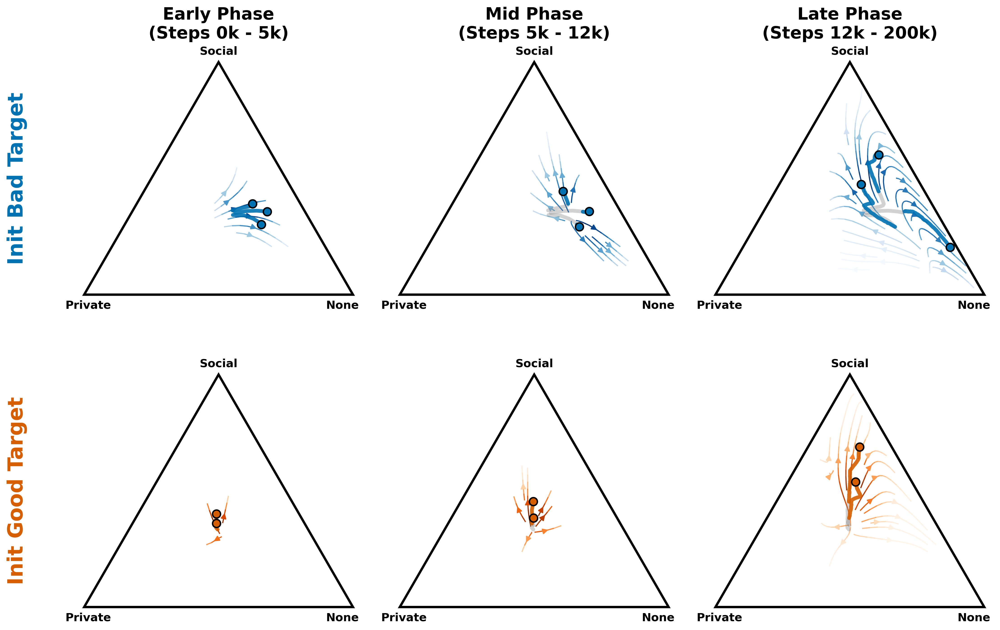

In [16]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import numpy.ma as ma
from scipy.stats import binned_statistic_2d
from scipy.ndimage import gaussian_filter
from matplotlib.patches import Polygon
from sklearn.cluster import KMeans

print("Calculating temporal gradients and overlaying trajectories...")

H = np.sqrt(3) / 2
df_gs = df_group_steps.copy()
df_gs['mx'] = df_gs['prob_none'] + 0.5 * df_gs['prob_soc']
df_gs['my'] = H * df_gs['prob_soc']

df_gs = df_gs.sort_values(['run_id', 'group_id', 'step'])
df_gs['dmx'] = df_gs.groupby(['run_id', 'group_id'])['mx'].diff()
df_gs['dmy'] = df_gs.groupby(['run_id', 'group_id'])['my'].diff()
df_gs = df_gs.dropna(subset=['dmx', 'dmy'])

df_gs['step'] -= 999
df_gs['step'] /= 1000
max_step = df_gs['step'].max()
time_bins = [0, 5, 12, 200]
time_labels = ['Early', 'Mid', 'Late']

conditions = df_gs['close_target_index'].unique()[:2]

# Pre-calculate clusters for each condition based on individual trajectories (groups)
cond_clusters = {}
for cond in conditions:
    cond_data = df_gs[df_gs['close_target_index'] == cond].copy()
    traj_features = cond_data.groupby(['run_id', 'group_id']).agg({
        'prob_soc': ['mean', 'last'],
        'prob_priv': ['mean', 'last']
    }).reset_index()
    traj_features.columns = ['run_id', 'group_id', 'soc_mean', 'soc_last', 'priv_mean', 'priv_last']
    
    X_features = traj_features[['soc_mean', 'soc_last', 'priv_mean', 'priv_last']].values
    kmeans = KMeans(n_clusters=3, random_state=42)
    traj_features['trajectory_class'] = kmeans.fit_predict(X_features)
    
    cluster_counts = traj_features['trajectory_class'].value_counts()
    top_2_classes = cluster_counts.nlargest(3).index.tolist()
    proportions = (cluster_counts / len(traj_features)).to_dict()
    traj_features['proportion'] = traj_features['trajectory_class'].map(proportions)
    
    cond_clustered = cond_data.merge(traj_features[['run_id', 'group_id', 'trajectory_class', 'proportion']], on=['run_id', 'group_id'])
    cond_clusters[cond] = {'data': cond_clustered, 'top_2': top_2_classes}

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
plt.rcParams.update({'font.size': 12})

grid_res = 35
x_bins = np.linspace(-0.05, 1.05, grid_res)
y_bins = np.linspace(-0.05, H + 0.05, grid_res)
X, Y = np.meshgrid(x_bins[:-1] + np.diff(x_bins)/2, y_bins[:-1] + np.diff(y_bins)/2)

colors_cond = {conditions[0]: 'Blues', conditions[1]: 'Oranges'}
title_colors = {conditions[0]: '#0072B2', conditions[1]: '#D55E00'}
# title_colors = {conditions[0]: '#7570b3', conditions[1]: '#d95f02'}

for row, cond in enumerate(conditions):
    cond_data = df_gs[df_gs['close_target_index'] == cond]
    
    for col, (t_start, t_end) in enumerate(zip(time_bins[:-1], time_bins[1:])):
        ax = axes[row, col]
        
        window_data = cond_data[(cond_data['step'] >= t_start) & (cond_data['step'] < t_end)]
        
        triangle = Polygon([[0, 0], [1, 0], [0.5, H]], fill=False, edgecolor='black', linewidth=2.5, zorder=4)
        ax.add_patch(triangle)
        
        if len(window_data) >= 50:
            U, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmx'], statistic='mean', bins=[x_bins, y_bins])
            V, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmy'], statistic='mean', bins=[x_bins, y_bins])
            Counts, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmx'], statistic='count', bins=[x_bins, y_bins])
            
            U, V, Counts = U.T, V.T, Counts.T
            
            U_smooth = gaussian_filter(np.nan_to_num(U, 0), sigma=1.0)
            V_smooth = gaussian_filter(np.nan_to_num(V, 0), sigma=1.0)
            
            mask = Counts < 5
            U_masked = ma.array(U_smooth, mask=mask)
            V_masked = ma.array(V_smooth, mask=mask)
            
            density = gaussian_filter(Counts, sigma=1.5)
            density_masked = ma.array(density, mask=mask)
            
            try:
                ax.streamplot(X, Y, U_masked, V_masked, color=density_masked, cmap=colors_cond[cond], 
                              linewidth=1.2, density=1.2, arrowsize=1.2, zorder=2)
            except ValueError:
                pass
                
        # ==========================================
        # Overlay Dominant Trajectories with Grayed History
        # ==========================================
        cond_info = cond_clusters[cond]
        cond_subset = cond_info['data']
        classes = cond_info['top_2']
        for class_id in classes:
            subset = cond_subset[cond_subset['trajectory_class'] == class_id]
            if subset.empty: continue
            if (cond == 0) & (class_id == 2): continue
            
            mean_traj = subset.groupby('step')[['prob_priv', 'prob_soc', 'prob_none']].mean().reset_index().sort_values('step')
            tmx = mean_traj['prob_none'] + 0.5 * mean_traj['prob_soc']
            tmy = H * mean_traj['prob_soc']
            tstep = mean_traj['step'].values
            proportion = subset['proportion'].iloc[0]
            lw = 4 # max(1.5, proportion * 20)
            
            idx_start = np.searchsorted(tstep, t_start)
            idx_end = np.searchsorted(tstep, t_end)
            idx_end = min(idx_end, len(tstep) - 1)
            
            if idx_start > 0:
                past_slice = slice(0, idx_start + 1)
                ax.plot(tmx.iloc[past_slice], tmy.iloc[past_slice], color='gray', linestyle='-', alpha=0.35, linewidth=lw, zorder=4, solid_capstyle='round')
            
            if idx_end > idx_start:
                curr_slice = slice(idx_start, idx_end + 1)
                curr_tmx = tmx.iloc[curr_slice]
                curr_tmy = tmy.iloc[curr_slice]
                
                ax.plot(curr_tmx, curr_tmy, color=title_colors[cond], linestyle='-', alpha=0.9, linewidth=lw, zorder=5, solid_capstyle='round')
                
                # if len(curr_tmx) > 3:
                #     arrow_indices = np.linspace(0, len(curr_tmx)-1, 3, dtype=int)[1:-1]
                #     look_ahead = max(1, len(curr_tmx) // 10)
                #     for idx in arrow_indices:
                #         idx_next = min(len(curr_tmx)-1, idx + look_ahead)
                #         ax.annotate('', xy=(curr_tmx.iloc[idx_next], curr_tmy.iloc[idx_next]), 
                #                     xytext=(curr_tmx.iloc[idx], curr_tmy.iloc[idx]),
                #                     arrowprops=dict(arrowstyle="->", color='black', lw=min(3, lw), alpha=0.9),
                #                     zorder=6)
                                    
                ax.scatter(curr_tmx.iloc[-1], curr_tmy.iloc[-1], color=title_colors[cond], edgecolor='black', marker='o', s=40 + lw*8, linewidth=1.5, zorder=7, alpha=1.0)
        
        ax.text(0.5, H + 0.02, "Social", ha='center', va='bottom', fontsize=12, weight='bold')
        ax.text(0.1, -0.02, "Private", ha='right', va='top', fontsize=12, weight='bold')
        ax.text(0.9, -0.02, "None", ha='left', va='top', fontsize=12, weight='bold')
        
        ax.axis('off')
        ax.set_aspect('equal')
        
        if row == 0:
            ax.set_title(f"{time_labels[col]} Phase\n(Steps {int(t_start)}k - {int(t_end)}k)", fontsize=18, weight='bold', pad=15)
    
    condition_name = 'Init Bad Target' if cond == 1 else 'Init Good Target'
    axes[row, 0].text(-0.25, H/2, condition_name, rotation=90, va='center', ha='center', 
                      fontsize=22, weight='bold', color=title_colors[cond])

# fig.suptitle("Temporal Change in Evolutionary Flow with Dominant Trajectories\n(Past trajectories are grayed out)", 
#              fontsize=24, weight='bold', y=1.02)

plt.tight_layout()
plt.subplots_adjust(left=0.08, top=0.90, hspace=0.1, wspace=0.1)
plt.savefig('group_trajectories.png', dpi=300)
plt.show()


Calculating temporal gradients and overlaying individual agent trajectories...


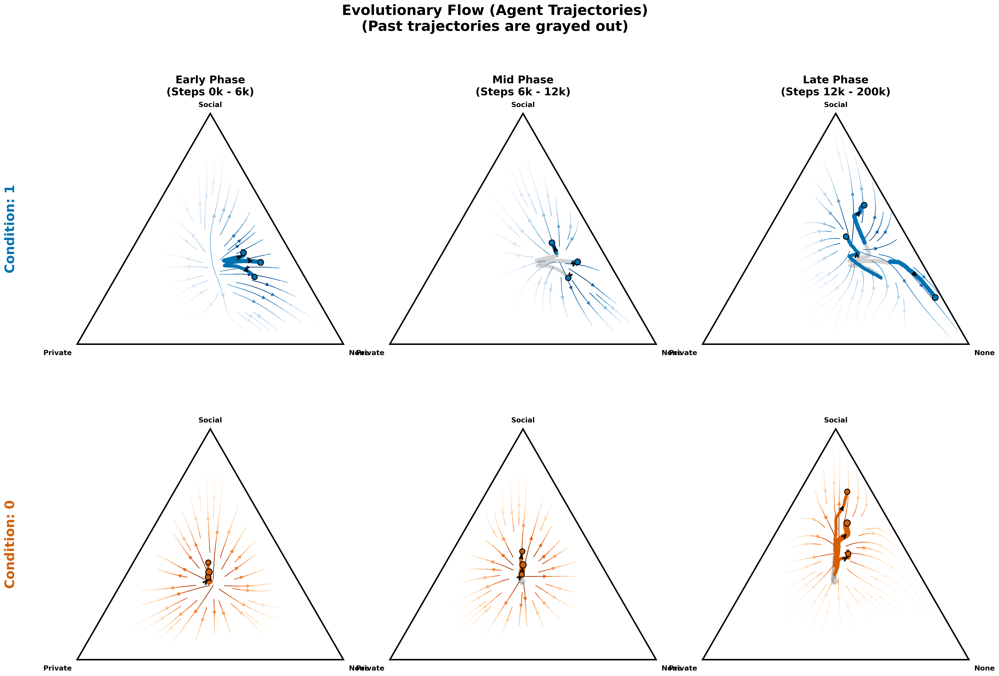

In [17]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import numpy.ma as ma
from scipy.stats import binned_statistic_2d
from scipy.ndimage import gaussian_filter
from matplotlib.patches import Polygon
from sklearn.cluster import KMeans

print("Calculating temporal gradients and overlaying individual agent trajectories...")

H = np.sqrt(3) / 2
# Use df_flow (or df) which contains individual agent steps
# Ensure it has the necessary probability columns
df_as = df_flow.copy() 

# Calculate coordinates in the simplex
df_as['mx'] = df_as['prob_none'] + 0.5 * df_as['prob_soc']
df_as['my'] = H * df_as['prob_soc']

# Sort and calculate temporal gradients per agent
df_as = df_as.sort_values(['run_id', 'group_id', 'agent_id', 'step'])
df_as['dmx'] = df_as.groupby(['run_id', 'group_id', 'agent_id'])['mx'].diff()
df_as['dmy'] = df_as.groupby(['run_id', 'group_id', 'agent_id'])['my'].diff()
df_as = df_as.dropna(subset=['dmx', 'dmy'])

# Normalize step for plotting (matches your original logic)
# Note: Ensure max_step is defined or use df_as['step'].max()
df_as['step_norm'] = (df_as['step'] - 999) / 1000
time_bins = [0, 6, 12, 200]
time_labels = ['Early', 'Mid', 'Late']

conditions = df_as['close_target_index'].unique()[:2]

# Pre-calculate clusters for each condition based on INDIVIDUAL agent trajectories
cond_clusters = {}
for cond in conditions:
    cond_data = df_as[df_as['close_target_index'] == cond].copy()
    
    # Feature engineering for individual agent trajectories
    traj_features = cond_data.groupby(['run_id', 'group_id', 'agent_id']).agg({
        'prob_soc': ['mean', 'last'],
        'prob_priv': ['mean', 'last']
    }).reset_index()
    
    # Flatten multi-index columns
    traj_features.columns = ['run_id', 'group_id', 'agent_id', 'soc_mean', 'soc_last', 'priv_mean', 'priv_last']
    
    X_features = traj_features[['soc_mean', 'soc_last', 'priv_mean', 'priv_last']].values
    kmeans = KMeans(n_clusters=3, random_state=42)
    traj_features['trajectory_class'] = kmeans.fit_predict(X_features)
    
    cluster_counts = traj_features['trajectory_class'].value_counts()
    top_classes = cluster_counts.nlargest(3).index.tolist()
    proportions = (cluster_counts / len(traj_features)).to_dict()
    traj_features['proportion'] = traj_features['trajectory_class'].map(proportions)
    
    cond_clustered = cond_data.merge(
        traj_features[['run_id', 'group_id', 'agent_id', 'trajectory_class', 'proportion']], 
        on=['run_id', 'group_id', 'agent_id']
    )
    cond_clusters[cond] = {'data': cond_clustered, 'top_classes': top_classes}

fig, axes = plt.subplots(2, 3, figsize=(24, 16))
plt.rcParams.update({'font.size': 12})

grid_res = 35
x_bins = np.linspace(-0.05, 1.05, grid_res)
y_bins = np.linspace(-0.05, H + 0.05, grid_res)
X, Y = np.meshgrid(x_bins[:-1] + np.diff(x_bins)/2, y_bins[:-1] + np.diff(y_bins)/2)

colors_cond = {conditions[0]: 'Blues', conditions[1]: 'Oranges'}
title_colors = {conditions[0]: '#0072B2', conditions[1]: '#D55E00'}

for row, cond in enumerate(conditions):
    cond_data = df_as[df_as['close_target_index'] == cond]
    
    for col, (t_start, t_end) in enumerate(zip(time_bins[:-1], time_bins[1:])):
        ax = axes[row, col]
        
        # Filter window data based on normalized step
        window_data = cond_data[(cond_data['step_norm'] >= t_start) & (cond_data['step_norm'] < t_end)]
        
        triangle = Polygon([[0, 0], [1, 0], [0.5, H]], fill=False, edgecolor='black', linewidth=2.5, zorder=4)
        ax.add_patch(triangle)
        
        if len(window_data) >= 50:
            # Calculate average flow based on individual agent transitions
            U, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmx'], statistic='mean', bins=[x_bins, y_bins])
            V, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmy'], statistic='mean', bins=[x_bins, y_bins])
            Counts, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmx'], statistic='count', bins=[x_bins, y_bins])
            
            U, V, Counts = U.T, V.T, Counts.T
            
            U_smooth = gaussian_filter(np.nan_to_num(U, 0), sigma=1.0)
            V_smooth = gaussian_filter(np.nan_to_num(V, 0), sigma=1.0)
            
            mask = Counts < 5
            U_masked = ma.array(U_smooth, mask=mask)
            V_masked = ma.array(V_smooth, mask=mask)
            
            density = gaussian_filter(Counts, sigma=1.5)
            density_masked = ma.array(density, mask=mask)
            
            try:
                ax.streamplot(X, Y, U_masked, V_masked, color=density_masked, cmap=colors_cond[cond], 
                              linewidth=1.2, density=1.2, arrowsize=1.2, zorder=2)
            except ValueError:
                pass
                
        # ==========================================
        # Overlay Dominant Agent Trajectories
        # ==========================================
        cond_info = cond_clusters[cond]
        cond_subset = cond_info['data']
        classes = cond_info['top_classes']
        for class_id in classes:
            subset = cond_subset[cond_subset['trajectory_class'] == class_id]
            if subset.empty: continue
            
            # Compute mean trajectory across all agents in this cluster
            mean_traj = subset.groupby('step_norm')[['prob_priv', 'prob_soc', 'prob_none']].mean().reset_index().sort_values('step_norm')
            tmx = mean_traj['prob_none'] + 0.5 * mean_traj['prob_soc']
            tmy = H * mean_traj['prob_soc']
            tstep = mean_traj['step_norm'].values
            
            proportion = subset['proportion'].iloc[0]
            lw = max(1.5, proportion * 20)
            
            idx_start = np.searchsorted(tstep, t_start)
            idx_end = np.searchsorted(tstep, t_end)
            idx_end = min(idx_end, len(tstep) - 1)
            
            # Grayed out past history
            if idx_start > 0:
                past_slice = slice(0, idx_start + 1)
                ax.plot(tmx.iloc[past_slice], tmy.iloc[past_slice], color='gray', linestyle='-', alpha=0.35, linewidth=lw, zorder=4, solid_capstyle='round')
            
            # Current phase trajectory
            if idx_end > idx_start:
                curr_slice = slice(idx_start, idx_end + 1)
                curr_tmx = tmx.iloc[curr_slice]
                curr_tmy = tmy.iloc[curr_slice]
                
                ax.plot(curr_tmx, curr_tmy, color=title_colors[cond], linestyle='-', alpha=1.0, linewidth=lw, zorder=5, solid_capstyle='round')
                
                # Direction arrows
                if len(curr_tmx) > 3:
                    arrow_indices = np.linspace(0, len(curr_tmx)-1, 3, dtype=int)[1:-1]
                    look_ahead = max(1, len(curr_tmx) // 10)
                    for idx in arrow_indices:
                        idx_next = min(len(curr_tmx)-1, idx + look_ahead)
                        ax.annotate('', xy=(curr_tmx.iloc[idx_next], curr_tmy.iloc[idx_next]), 
                                    xytext=(curr_tmx.iloc[idx], curr_tmy.iloc[idx]),
                                    arrowprops=dict(arrowstyle="->", color='black', lw=min(3, lw), alpha=0.9),
                                    zorder=6)
                                    
                ax.scatter(curr_tmx.iloc[-1], curr_tmy.iloc[-1], color=title_colors[cond], edgecolor='black', marker='o', s=40 + lw*8, linewidth=1.5, zorder=7, alpha=1.0)
        
        # Labels and formatting
        ax.text(0.5, H + 0.02, "Social", ha='center', va='bottom', fontsize=12, weight='bold')
        ax.text(-0.02, -0.02, "Private", ha='right', va='top', fontsize=12, weight='bold')
        ax.text(1.02, -0.02, "None", ha='left', va='top', fontsize=12, weight='bold')
        
        ax.axis('off')
        ax.set_aspect('equal')
        
        if row == 0:
            ax.set_title(f"{time_labels[col]} Phase\n(Steps {int(t_start)}k - {int(t_end)}k)", fontsize=18, weight='bold', pad=15)
            
    axes[row, 0].text(-0.25, H/2, f"Condition: {cond}", rotation=90, va='center', ha='center', 
                      fontsize=22, weight='bold', color=title_colors[cond])

fig.suptitle("Evolutionary Flow (Agent Trajectories)\n(Past trajectories are grayed out)", 
             fontsize=24, weight='bold', y=1.02)

plt.tight_layout()
plt.subplots_adjust(left=0.08, top=0.90, hspace=0.1, wspace=0.1)
plt.show()


## Animated Temporal Change
Generates an animated GIF of the temporal change in evolutionary flow with dominant trajectories, using a sliding window across the simulation steps.

Preparing animation... This may take a minute.


IndexError: list index out of range

Error in callback <function _draw_all_if_interactive at 0x7ff36c327d80> (for post_execute), with arguments args (),kwargs {}:


KeyError: 'top_2'

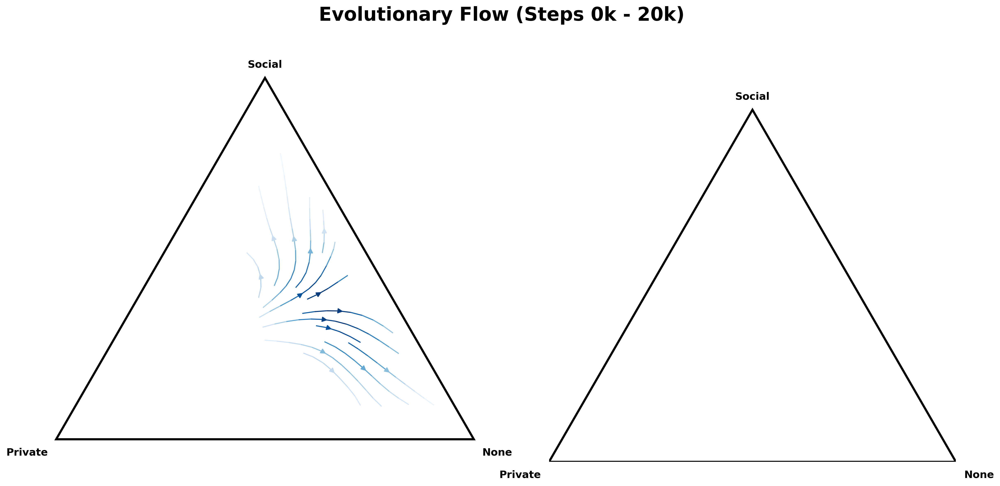

In [18]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import numpy.ma as ma
from scipy.stats import binned_statistic_2d
from scipy.ndimage import gaussian_filter
from matplotlib.patches import Polygon
from matplotlib.animation import FuncAnimation
from IPython.display import Image, display

print("Preparing animation... This may take a minute.")

# Use df_gs and cond_clusters from the previous cell
max_step = df_gs['step'].max()
window_size = 20  # Size of the time window in scaled steps
step_size = 2     # How much to slide the window per frame

frames = int((max_step - window_size) / step_size) + 1

conditions = df_gs['close_target_index'].unique()[:2]
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
plt.rcParams.update({'font.size': 12})

H = np.sqrt(3) / 2
grid_res = 35
x_bins = np.linspace(-0.05, 1.05, grid_res)
y_bins = np.linspace(-0.05, H + 0.05, grid_res)
X, Y = np.meshgrid(x_bins[:-1] + np.diff(x_bins)/2, y_bins[:-1] + np.diff(y_bins)/2)

colors_cond = {conditions[0]: 'Blues', conditions[1]: 'Oranges'}
title_colors = {conditions[0]: '#0072B2', conditions[1]: '#D55E00'}

def update(frame_idx):
    t_start = frame_idx * step_size
    t_end = t_start + window_size
    
    for ax in axes:
        ax.clear()
        triangle = Polygon([[0, 0], [1, 0], [0.5, H]], fill=False, edgecolor='black', linewidth=2.5, zorder=4)
        ax.add_patch(triangle)
        ax.text(0.5, H + 0.02, "Social", ha='center', va='bottom', fontsize=12, weight='bold')
        ax.text(-0.02, -0.02, "Private", ha='right', va='top', fontsize=12, weight='bold')
        ax.text(1.02, -0.02, "None", ha='left', va='top', fontsize=12, weight='bold')
        ax.axis('off')
        ax.set_aspect('equal')
        
    fig.suptitle(f"Evolutionary Flow (Steps {int(t_start)}k - {int(t_end)}k)", fontsize=22, weight='bold', y=0.98)
    
    for col, cond in enumerate(conditions):
        ax = axes[col]
        cond_data = df_gs[df_gs['close_target_index'] == cond]
        window_data = cond_data[(cond_data['step'] >= t_start) & (cond_data['step'] < t_end)]
        
        if len(window_data) >= 20:
            U, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmx'], statistic='mean', bins=[x_bins, y_bins])
            V, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmy'], statistic='mean', bins=[x_bins, y_bins])
            Counts, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmx'], statistic='count', bins=[x_bins, y_bins])
            
            U, V, Counts = U.T, V.T, Counts.T
            
            U_smooth = gaussian_filter(np.nan_to_num(U, 0), sigma=1.0)
            V_smooth = gaussian_filter(np.nan_to_num(V, 0), sigma=1.0)
            
            mask = Counts < 3
            U_masked = ma.array(U_smooth, mask=mask)
            V_masked = ma.array(V_smooth, mask=mask)
            
            density = gaussian_filter(Counts, sigma=1.5)
            density_masked = ma.array(density, mask=mask)
            
            try:
                ax.streamplot(X, Y, U_masked, V_masked, color=density_masked, cmap=colors_cond[cond], 
                              linewidth=1.2, density=1.2, arrowsize=1.2, zorder=2)
            except ValueError:
                pass
                
        # Overlay Dominant Trajectories
        if 'cond_clusters' in globals() or 'cond_clusters' in locals():
            cond_info = cond_clusters[cond]
            cond_subset = cond_info['data']
            classes = cond_info['top_2']
            for class_id in classes:
                subset = cond_subset[cond_subset['trajectory_class'] == class_id]
                if subset.empty: continue
                
                mean_traj = subset.groupby('step')[['prob_priv', 'prob_soc', 'prob_none']].mean().reset_index().sort_values('step')
                tmx = mean_traj['prob_none'] + 0.5 * mean_traj['prob_soc']
                tmy = H * mean_traj['prob_soc']
                tstep = mean_traj['step'].values
                proportion = subset['proportion'].iloc[0]
                lw = max(1.5, proportion * 20)
                
                idx_start = np.searchsorted(tstep, t_start)
                idx_end = np.searchsorted(tstep, t_end)
                idx_end = min(idx_end, len(tstep) - 1)
                
                if idx_start > 0:
                    past_slice = slice(0, idx_start + 1)
                    ax.plot(tmx.iloc[past_slice], tmy.iloc[past_slice], color='gray', linestyle='-', alpha=0.35, linewidth=lw, zorder=4, solid_capstyle='round')
                
                if idx_end > idx_start:
                    curr_slice = slice(idx_start, idx_end + 1)
                    curr_tmx = tmx.iloc[curr_slice]
                    curr_tmy = tmy.iloc[curr_slice]
                    
                    ax.plot(curr_tmx, curr_tmy, color=title_colors[cond], linestyle='-', alpha=1.0, linewidth=lw, zorder=5, solid_capstyle='round')
                    
                    if len(curr_tmx) > 3:
                        arrow_indices = np.linspace(0, len(curr_tmx)-1, 3, dtype=int)[1:-1]
                        look_ahead = max(1, len(curr_tmx) // 10)
                        for idx in arrow_indices:
                            idx_next = min(len(curr_tmx)-1, idx + look_ahead)
                            ax.annotate('', xy=(curr_tmx.iloc[idx_next], curr_tmy.iloc[idx_next]), 
                                        xytext=(curr_tmx.iloc[idx], curr_tmy.iloc[idx]),
                                        arrowprops=dict(arrowstyle="->", color='black', lw=min(3, lw), alpha=0.9),
                                        zorder=6)
                                        
                    ax.scatter(curr_tmx.iloc[-1], curr_tmy.iloc[-1], color=title_colors[cond], edgecolor='black', marker='o', s=40 + lw*8, linewidth=1.5, zorder=7, alpha=1.0)
                    
        ax.set_title(f"Condition: {cond}", fontsize=18, weight='bold', color=title_colors[cond], pad=15)

plt.tight_layout()
plt.subplots_adjust(top=0.88)

anim = FuncAnimation(fig, update, frames=frames, interval=250)
gif_path = "evolution_flow.gif"
anim.save(gif_path, writer='pillow', fps=4)
plt.close() # Prevent static plot from displaying

print(f"Animation saved to {gif_path}")
display(Image(filename=gif_path))


In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import numpy.ma as ma
from scipy.stats import binned_statistic_2d
from scipy.ndimage import gaussian_filter
from matplotlib.patches import Polygon
from matplotlib.animation import FuncAnimation
from IPython.display import Image, Video, display

print("Preparing animation and saving frames... This may take a minute.")

frames_dir = 'animation_frames'
os.makedirs(frames_dir, exist_ok=True)

# Use df_gs and cond_clusters from the previous cell
max_step = df_gs['step'].max()
window_size = 2  # Size of the time window in scaled steps
step_size = 2     # How much to slide the window per frame

frames = int((max_step - window_size) / step_size) + 1

conditions = df_gs['close_target_index'].unique()[:2]
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
plt.rcParams.update({'font.size': 12})

H = np.sqrt(3) / 2
grid_res = 35
x_bins = np.linspace(-0.05, 1.05, grid_res)
y_bins = np.linspace(-0.05, H + 0.05, grid_res)
X, Y = np.meshgrid(x_bins[:-1] + np.diff(x_bins)/2, y_bins[:-1] + np.diff(y_bins)/2)

colors_cond = {conditions[0]: 'Blues', conditions[1]: 'Oranges'}
title_colors = {conditions[0]: '#0072B2', conditions[1]: '#D55E00'}

def update(frame_idx):
    t_start = frame_idx * step_size
    t_end = t_start + window_size
    
    for ax in axes:
        ax.clear()
        triangle = Polygon([[0, 0], [1, 0], [0.5, H]], fill=False, edgecolor='black', linewidth=2.5, zorder=4)
        ax.add_patch(triangle)
        ax.text(0.5, H + 0.02, "Social", ha='center', va='bottom', fontsize=12, weight='bold')
        ax.text(-0.02, -0.02, "Private", ha='right', va='top', fontsize=12, weight='bold')
        ax.text(1.02, -0.02, "None", ha='left', va='top', fontsize=12, weight='bold')
        ax.axis('off')
        ax.set_aspect('equal')
        
    fig.suptitle(f"Evolutionary Flow (Steps {int(t_start)}k - {int(t_end)}k)", fontsize=22, weight='bold', y=0.98)
    
    for col, cond in enumerate(conditions):
        ax = axes[col]
        cond_data = df_gs[df_gs['close_target_index'] == cond]
        window_data = cond_data[(cond_data['step'] >= t_start) & (cond_data['step'] < t_end)]
        
        if len(window_data) >= 20:
            U, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmx'], statistic='mean', bins=[x_bins, y_bins])
            V, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmy'], statistic='mean', bins=[x_bins, y_bins])
            Counts, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmx'], statistic='count', bins=[x_bins, y_bins])
            
            U, V, Counts = U.T, V.T, Counts.T
            
            U_smooth = gaussian_filter(np.nan_to_num(U, 0), sigma=1.0)
            V_smooth = gaussian_filter(np.nan_to_num(V, 0), sigma=1.0)
            
            mask = Counts < 3
            U_masked = ma.array(U_smooth, mask=mask)
            V_masked = ma.array(V_smooth, mask=mask)
            
            density = gaussian_filter(Counts, sigma=1.5)
            density_masked = ma.array(density, mask=mask)
            
            try:
                ax.streamplot(X, Y, U_masked, V_masked, color=density_masked, cmap=colors_cond[cond], 
                              linewidth=1.2, density=1.2, arrowsize=1.2, zorder=2)
            except ValueError:
                pass
                
        # Overlay Dominant Trajectories
        if 'cond_clusters' in globals() or 'cond_clusters' in locals():
            cond_info = cond_clusters[cond]
            cond_subset = cond_info['data']
            classes = cond_info['top_2']
            for class_id in classes:
                subset = cond_subset[cond_subset['trajectory_class'] == class_id]
                if subset.empty: continue
                
                mean_traj = subset.groupby('step')[['prob_priv', 'prob_soc', 'prob_none']].mean().reset_index().sort_values('step')
                tmx = mean_traj['prob_none'] + 0.5 * mean_traj['prob_soc']
                tmy = H * mean_traj['prob_soc']
                tstep = mean_traj['step'].values
                proportion = subset['proportion'].iloc[0]
                lw = max(1.5, proportion * 20)
                
                idx_start = np.searchsorted(tstep, t_start)
                idx_end = np.searchsorted(tstep, t_end)
                idx_end = min(idx_end, len(tstep) - 1)
                
                if idx_start > 0:
                    past_slice = slice(0, idx_start + 1)
                    ax.plot(tmx.iloc[past_slice], tmy.iloc[past_slice], color='gray', linestyle='-', alpha=0.35, linewidth=lw, zorder=4, solid_capstyle='round')
                
                if idx_end > idx_start:
                    curr_slice = slice(idx_start, idx_end + 1)
                    curr_tmx = tmx.iloc[curr_slice]
                    curr_tmy = tmy.iloc[curr_slice]
                    
                    ax.plot(curr_tmx, curr_tmy, color=title_colors[cond], linestyle='-', alpha=1.0, linewidth=lw, zorder=5, solid_capstyle='round')
                    
                    if len(curr_tmx) > 3:
                        arrow_indices = np.linspace(0, len(curr_tmx)-1, 3, dtype=int)[1:-1]
                        look_ahead = max(1, len(curr_tmx) // 10)
                        for idx in arrow_indices:
                            idx_next = min(len(curr_tmx)-1, idx + look_ahead)
                            ax.annotate('', xy=(curr_tmx.iloc[idx_next], curr_tmy.iloc[idx_next]), 
                                        xytext=(curr_tmx.iloc[idx], curr_tmy.iloc[idx]),
                                        arrowprops=dict(arrowstyle="->", color='black', lw=min(3, lw), alpha=0.9),
                                        zorder=6)
                                        
                    ax.scatter(curr_tmx.iloc[-1], curr_tmy.iloc[-1], color=title_colors[cond], edgecolor='black', marker='o', s=40 + lw*8, linewidth=1.5, zorder=7, alpha=1.0)
                    
        ax.set_title(f"Condition: {cond}", fontsize=18, weight='bold', color=title_colors[cond], pad=15)
        
    plt.tight_layout()
    plt.subplots_adjust(top=0.88)
    
    # Save the individual frame
    plt.savefig(os.path.join(frames_dir, f"frame_{frame_idx:03d}.png"), dpi=100, bbox_inches='tight')

anim = FuncAnimation(fig, update, frames=frames, interval=250)

# Save as GIF
gif_path = "evolution_flow.gif"
anim.save(gif_path, writer='pillow', fps=4)

# Save as MP4
mp4_path = "evolution_flow.mp4"
try:
    anim.save(mp4_path, writer='ffmpeg', fps=4)
    print(f"Animation saved to {gif_path} and {mp4_path}")
    print(f"Individual frames saved to directory: '{os.path.abspath(frames_dir)}'")
    display(Video(mp4_path, embed=True))
except Exception as e:
    print(f"Could not save MP4 (is ffmpeg installed?): {e}")
    print(f"Animation saved to {gif_path}")
    print(f"Individual frames saved to directory: '{os.path.abspath(frames_dir)}'")
    display(Image(filename=gif_path))

plt.close() # Prevent static plot from displaying


Preparing animation and saving frames... This may take a minute.
Animation saved to evolution_flow.gif and evolution_flow.mp4
Individual frames saved to directory: '/home/chirkov/ct_marl/Social-Foraging-in-Dynamic-Environments-Balancing-Information-Channels/animation_frames'


## Analysis based on splitting data by whether the group found the target

Calculating temporal gradients and overlaying trajectories...


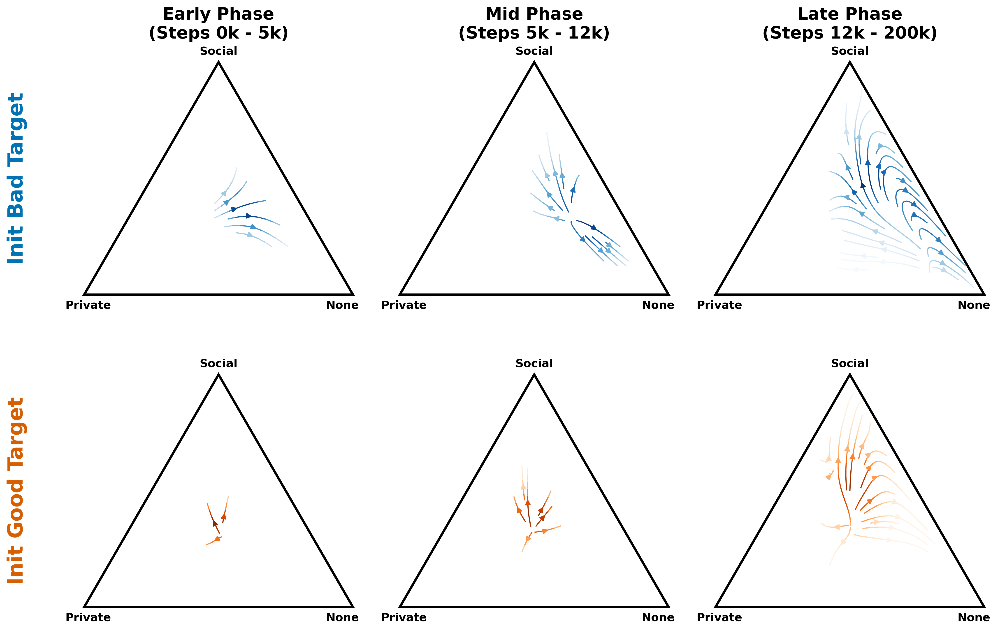

In [ ]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import numpy.ma as ma
from scipy.stats import binned_statistic_2d
from scipy.ndimage import gaussian_filter
from matplotlib.patches import Polygon
from sklearn.cluster import KMeans

print("Calculating temporal gradients and overlaying trajectories...")

H = np.sqrt(3) / 2
df_gs = df_group_steps.copy()
df_gs['mx'] = df_gs['prob_none'] + 0.5 * df_gs['prob_soc']
df_gs['my'] = H * df_gs['prob_soc']

df_gs = df_gs.sort_values(['run_id', 'group_id', 'step'])
df_gs['dmx'] = df_gs.groupby(['run_id', 'group_id'])['mx'].diff()
df_gs['dmy'] = df_gs.groupbxqy(['run_id', 'group_id'])['my'].diff()
df_gs = df_gs.dropna(subset=['dmx', 'dmy'])

df_gs['step'] -= 999
df_gs['step'] /= 1000
max_step = df_gs['step'].max()
time_bins = [0, 5, 12, 200]
time_labels = ['Early', 'Mid', 'Late']

conditions = df_gs['close_target_index'].unique()[:2]

# Pre-calculate clusters for each condition based on individual trajectories (groups)
cond_clusters = {}
for cond in conditions:
    cond_data = df_gs[df_gs['close_target_index'] == cond].copy()
    traj_features = cond_data.groupby(['run_id', 'group_id']).agg({
        'prob_soc': ['mean', 'last'],
        'prob_priv': ['mean', 'last']
    }).reset_index()
    traj_features.columns = ['run_id', 'group_id', 'soc_mean', 'soc_last', 'priv_mean', 'priv_last']
    
    X_features = traj_features[['soc_mean', 'soc_last', 'priv_mean', 'priv_last']].values
    kmeans = KMeans(n_clusters=3, random_state=42)
    traj_features['trajectory_class'] = kmeans.fit_predict(X_features)
    
    cluster_counts = traj_features['trajectory_class'].value_counts()
    top_2_classes = cluster_counts.nlargest(3).index.tolist()
    proportions = (cluster_counts / len(traj_features)).to_dict()
    traj_features['proportion'] = traj_features['trajectory_class'].map(proportions)
    
    cond_clustered = cond_data.merge(traj_features[['run_id', 'group_id', 'trajectory_class', 'proportion']], on=['run_id', 'group_id'])
    cond_clusters[cond] = {'data': cond_clustered, 'top_2': top_2_classes}

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
plt.rcParams.update({'font.size': 12})

grid_res = 35
x_bins = np.linspace(-0.05, 1.05, grid_res)
y_bins = np.linspace(-0.05, H + 0.05, grid_res)
X, Y = np.meshgrid(x_bins[:-1] + np.diff(x_bins)/2, y_bins[:-1] + np.diff(y_bins)/2)

colors_cond = {conditions[0]: 'Blues', conditions[1]: 'Oranges'}
title_colors = {conditions[0]: '#0072B2', conditions[1]: '#D55E00'}
# title_colors = {conditions[0]: '#7570b3', conditions[1]: '#d95f02'}

for row, cond in enumerate(conditions):
    cond_data = df_gs[df_gs['close_target_index'] == cond]
    
    for col, (t_start, t_end) in enumerate(zip(time_bins[:-1], time_bins[1:])):
        ax = axes[row, col]
        
        window_data = cond_data[(cond_data['step'] >= t_start) & (cond_data['step'] < t_end)]
        
        triangle = Polygon([[0, 0], [1, 0], [0.5, H]], fill=False, edgecolor='black', linewidth=2.5, zorder=4)
        ax.add_patch(triangle)
        
        if len(window_data) >= 50:
            U, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmx'], statistic='mean', bins=[x_bins, y_bins])
            V, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmy'], statistic='mean', bins=[x_bins, y_bins])
            Counts, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmx'], statistic='count', bins=[x_bins, y_bins])
            
            U, V, Counts = U.T, V.T, Counts.T
            
            U_smooth = gaussian_filter(np.nan_to_num(U, 0), sigma=1.0)
            V_smooth = gaussian_filter(np.nan_to_num(V, 0), sigma=1.0)
            
            mask = Counts < 5
            U_masked = ma.array(U_smooth, mask=mask)
            V_masked = ma.array(V_smooth, mask=mask)
            
            density = gaussian_filter(Counts, sigma=1.5)
            density_masked = ma.array(density, mask=mask)
            
            try:
                ax.streamplot(X, Y, U_masked, V_masked, color=density_masked, cmap=colors_cond[cond], 
                              linewidth=1.2, density=1.2, arrowsize=1.2, zorder=2)
            except ValueError:
                pass
        
        ax.text(0.5, H + 0.02, "Social", ha='center', va='bottom', fontsize=12, weight='bold')
        ax.text(0.1, -0.02, "Private", ha='right', va='top', fontsize=12, weight='bold')
        ax.text(0.9, -0.02, "None", ha='left', va='top', fontsize=12, weight='bold')
        
        ax.axis('off')
        ax.set_aspect('equal')
        
        if row == 0:
            ax.set_title(f"{time_labels[col]} Phase\n(Steps {int(t_start)}k - {int(t_end)}k)", fontsize=18, weight='bold', pad=15)
    
    condition_name = 'Init Bad Target' if cond == 1 else 'Init Good Target'
    axes[row, 0].text(-0.25, H/2, condition_name, rotation=90, va='center', ha='center', 
                      fontsize=22, weight='bold', color=title_colors[cond])

plt.tight_layout()
plt.subplots_adjust(left=0.08, top=0.90, hspace=0.1, wspace=0.1)
plt.savefig('group_trajectories.png', dpi=300)
plt.show()


In [22]:
df

,group_id,agent_id,age,cumulative_fitness,current_fitness,avg_fitness,gene_priv,gene_soc,gene_none,gene_eve,run_id,close_target_index,step,p_priv,p_soc,p_none
0,0.0,0.0,1000.0,809.989380,0.811950,0.809989,0.367425,-0.240265,0.075739,-0.644270,lck2wafo,0,999,0.436374,0.237653,0.325973
1,0.0,1.0,1000.0,801.374146,0.793795,0.801374,0.987102,-0.111018,0.310793,0.440495,lck2wafo,0,999,0.542892,0.181053,0.276055
2,0.0,2.0,1000.0,836.685059,0.828782,0.836685,0.150497,0.472290,-0.321096,-0.453458,lck2wafo,0,999,0.332933,0.459314,0.207753
3,0.0,3.0,1000.0,824.242065,0.833711,0.824242,0.067888,-0.256189,-0.435010,0.634646,lck2wafo,0,999,0.429559,0.310655,0.259787
4,0.0,4.0,1000.0,797.704956,0.835471,0.797705,0.249322,-0.082900,-0.556916,0.113567,lck2wafo,0,999,0.462137,0.331503,0.206360
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5999995,999.0,10.0,15000.0,569.163513,0.004673,0.569164,-1.640297,0.510617,2.062319,0.067143,dment0yi,1,199999,0.019942,0.171354,0.808704
5999996,999.0,11.0,6000.0,602.315186,0.003679,0.602315,-1.678847,0.480552,1.857703,-0.021127,dment0yi,1,199999,0.022720,0.196890,0.780390
5999997,999.0,12.0,7000.0,561.124634,0.002454,0.561125,-1.744566,0.487114,1.889013,0.044970,dment0yi,1,199999,0.020763,0.193414,0.785823
5999998,999.0,13.0,12000.0,560.057068,0.003736,0.560057,-1.427274,0.461211,2.107701,0.115944,dment0yi,1,199999,0.023864,0.157728,0.818408
